In [1]:
import matplotlib.pyplot as plt
from dstools.dynamic_spectrum import DynamicSpectrum, LightCurve
from dstools.plotting import plot_ds, plot_lightcurve
import os
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.patches import Rectangle
import astropy.constants as c
import astropy.units as u
from scipy.optimize import curve_fit
from scipy.optimize import brentq
import lightkurve as lk
from astropy.timeseries import LombScargle
from astropy.time import Time
from matplotlib.ticker import MaxNLocator
from astropy.coordinates import SkyCoord, EarthLocation
from astropy.table import Table

Separate by sector before making phase folds.

# HD 104919

Instead of stitching everything together: Select all of our sectors and just download/analyse one at a time.

In [153]:
lc_list = lk.search_lightcurve('HD 104919', author='QLP')

In [154]:
lc_list

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 11,2019,QLP,1800,379769581,0.0
1,TESS Sector 37,2021,QLP,600,379769581,0.0
2,TESS Sector 38,2021,QLP,600,379769581,0.0
3,TESS Sector 64,2023,QLP,200,379769581,0.0
4,TESS Sector 65,2023,QLP,200,379769581,0.0
5,TESS Sector 100,2026,QLP,200,379769581,0.0
6,TESS Sector 99,2026,QLP,600,379769581,0.0


In [155]:
lc_all = lc_list.download_all().stitch()

In [162]:
lc = lc_list[1].download()

Here is our first TESS sector, very pretty looking

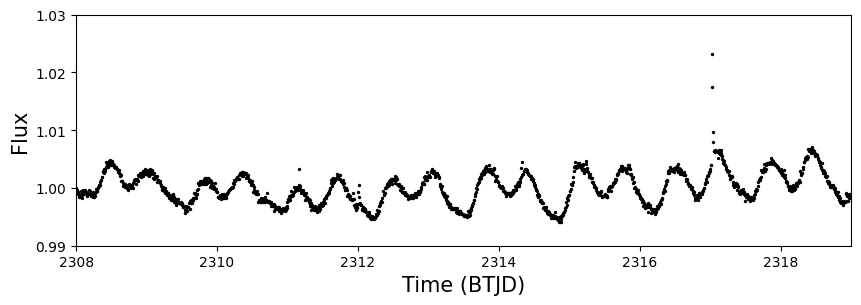

In [165]:
plt.figure(figsize = (10,3))
plt.scatter(lc.time.value, lc.flux.value, s = 2, c = 'black')
plt.ylim(0.99,1.03)
plt.xlim(2308,2319)
plt.xlabel('Time (BTJD)', fontsize=15)
plt.ylabel('Flux',fontsize=15)
# plt.title('HD 104919 TESS Sector 37',fontsize=20)
plt.savefig('thesis_figs/hd104919-tess-lc.pdf', dpi=300)

See if we can get some periodicity out of this with a Lomb-Scargle:

In [80]:
def calc_lomb_scargle(t, y):

    # remove NaNs
    mask = np.isfinite(t) & np.isfinite(y)
    t = t[mask]
    y = y[mask]

    # remove mean
    y = y - np.mean(y)

    oversample = 10

    tspan = t.max() - t.min()
    df = 1.0 / tspan

    fmin = df
    fmax = 25  # cycles/day

    freq = np.arange(fmin, fmax, df / oversample)

    model = LombScargle(t, y)
    power = model.power(freq)

    # simple amplitude estimate (relative, not absolute physical ppm)
    amp = np.sqrt(power)

    return freq, amp

In [156]:
freq, amp = calc_lomb_scargle(lc_all.time.value, lc_all.flux.value)

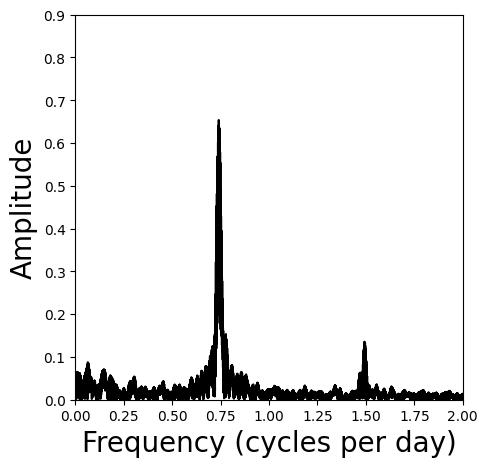

In [161]:
plt.figure(figsize = (5,5))
plt.plot(freq,amp, c = 'black')
plt.xlim(0,2)
plt.ylim(0,0.9)
plt.xlabel('Frequency (cycles per day)', fontsize=20)
plt.ylabel('Amplitude', fontsize=20)

plt.savefig('thesis_figs/hd104919-periodogram.pdf', dpi=300)
# plt.title('Periodogram - all TESS data', fontsize=20)

Let's be naive and take this maximum peak as our periodicity.

In [13]:
highest_power = np.argmax(amp)
print(freq[highest_power]) 

0.7612046103649863


Also calculate a phase so we can fold our lightcurve:

In [14]:
period = 1 / (freq[highest_power])
phase = (lc.time.value / period)%1
print(period)

1.3137072298084411


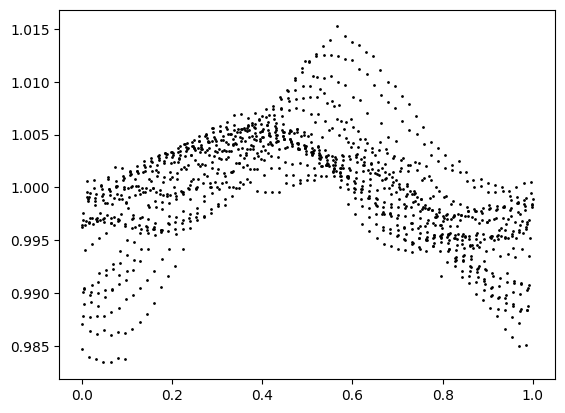

In [15]:
plt.scatter(phase, lc.flux.value, c = 'black', s = 1)

And we can see this isnt a good fit. Looks to me like we have a harmonic of our period, so let's try a period 1/2 as large:

In [16]:
period_new = period / 2

In [17]:
phase_new = (lc.time.value / period_new)%1

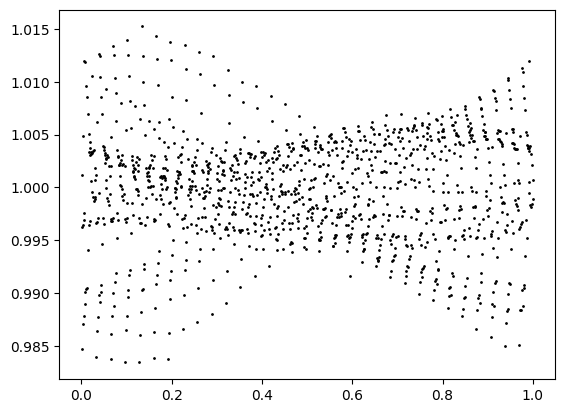

In [18]:
plt.scatter(phase_new, lc.flux.value, c = 'black', s = 1)

The fact I can't get this to work is making me suspicious about using even a whole sector at once. Note there is a downlink break in the middle, what if we cut our data there, re-perform our lomb scargle, and see if we can get a period out of those individually?

(1609.0, 1611.0)

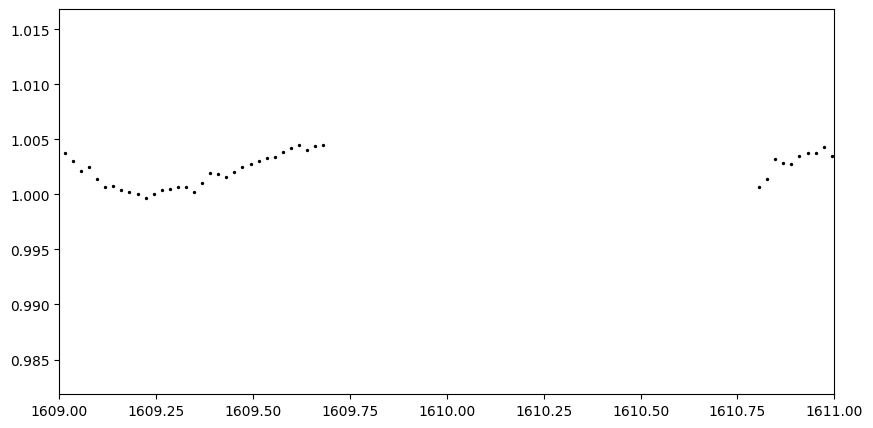

In [79]:
plt.figure(figsize = (10,5))
plt.scatter(lc.time.value, lc.flux.value, s = 2, c = 'black')
plt.xlim(1609,1611)

In [80]:
first_half = lc.time.value < 1610

time1 = lc.time.value[first_half]
flux1 = lc.flux.value[first_half]

time2 = lc.time.value[~first_half]
flux2 = lc.flux.value[~first_half]

In [81]:
freq1, amp1 = calc_lomb_scargle(time1, flux1)
freq2, amp2 = calc_lomb_scargle(time2, flux2)

In [82]:
highest_power1 = np.argmax(amp1)
highest_power2 = np.argmax(amp2)

In [83]:
period1 = 1 / (freq1[highest_power1])
phase1 = (time1 / period1)%1

period2 = 1 / (freq2[highest_power2])
phase2 = (time2 / period2)%1

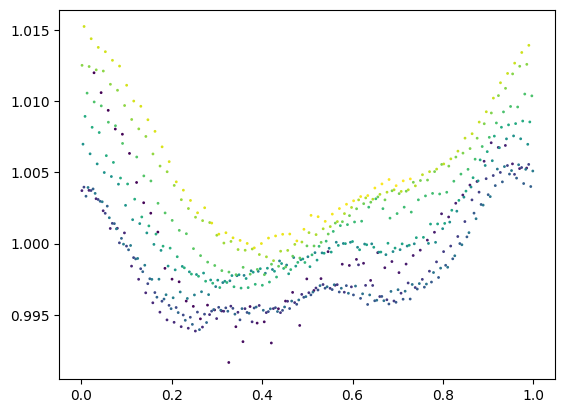

In [84]:
plt.scatter(phase1, flux1, c = time1, cmap = 'viridis', s = 1)

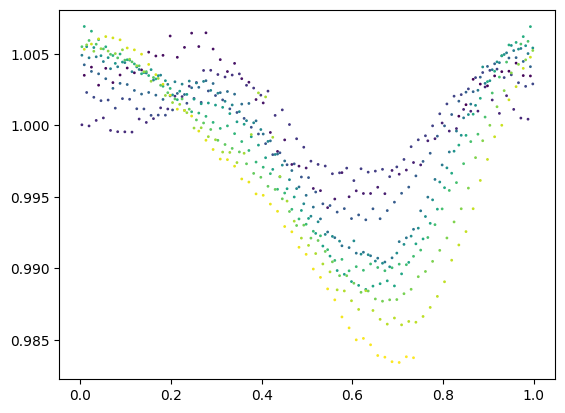

In [85]:
plt.scatter(phase2, flux2, c = time2, cmap = 'viridis', s = 1)

Here we are. To me, it looks like we have the right period, but we also have some other sort of variability throughout these epochs. Cool!

In [86]:
print(period1, period2)

1.327322467041766 1.3194295555567428


Our periods are also very similar, but given we have a whole lot of epochs, this could mean that we can estimate a period error for this source.

We want a way to generalise this for all TESS epochs without manually doing the cuts. 

In [89]:
np.argmax(np.diff(lc.time.value))

np.int64(615)

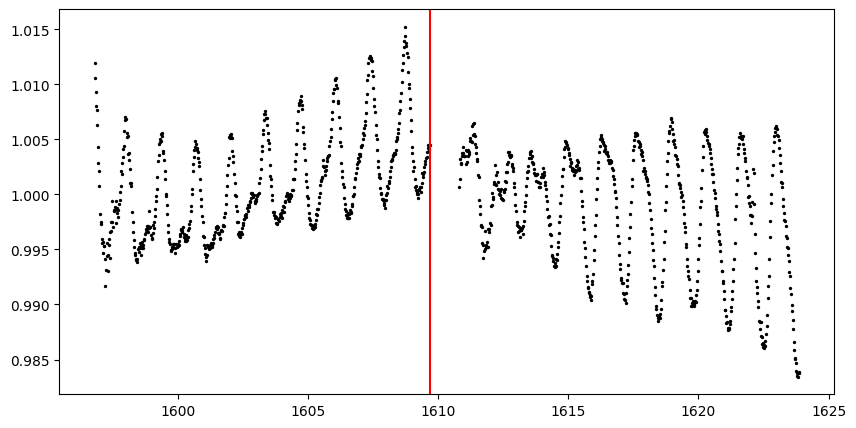

In [112]:
plt.figure(figsize = (10,5))
plt.scatter(lc.time.value, lc.flux.value, s = 2, c = 'black')
plt.axvline(lc.time.value[np.argmax(np.diff(lc.time.value))], c = 'red')
# plt.xlim(1609,1611)

So we can find a gap like this. We can also look at the median gap:

In [96]:
np.median(np.diff(lc.time.value))*24*60*60

np.float64(1799.9867852748139)

i.e. 1800 second cadence

In [97]:
lc_list

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 11,2019,QLP,1800,379769581,0.0
1,TESS Sector 37,2021,QLP,600,379769581,0.0
2,TESS Sector 38,2021,QLP,600,379769581,0.0
3,TESS Sector 64,2023,QLP,200,379769581,0.0
4,TESS Sector 65,2023,QLP,200,379769581,0.0
5,TESS Sector 100,2026,QLP,200,379769581,0.0
6,TESS Sector 99,2026,QLP,600,379769581,0.0


In [104]:
lc_list[0].exptime.value[0]

np.float64(1800.0)

We can use these cadences to identify gaps, so let's try and generalise this to our set of lightcurves.

In [167]:
def segment_lc(lc, cadence):

    # Find the time and cadence of our observation
    time = lc.time.value

    # Identify any gaps in our LC
    gaps = np.where(np.diff(time) > cadence * 10)[0]

    # Slice our arrays into separate lightcurves
    starts = np.r_[0, gaps + 1]
    ends = np.r_[gaps + 1, len(lc)]
    lc_segments = [lc[start:end] for start, end in zip(starts, ends)]

    return lc_segments

In [168]:
def find_phase(lc):

    # Perform a Lomb Scargle
    freq, amp = calc_lomb_scargle(lc.time.value, lc.flux.value)

    # Take the peak to be the periodicity
    highest_power = np.argmax(amp)

    period = 1 / (freq[highest_power])
    phase = (lc.time.value / period)%1

    return period, phase

12.875027930305123


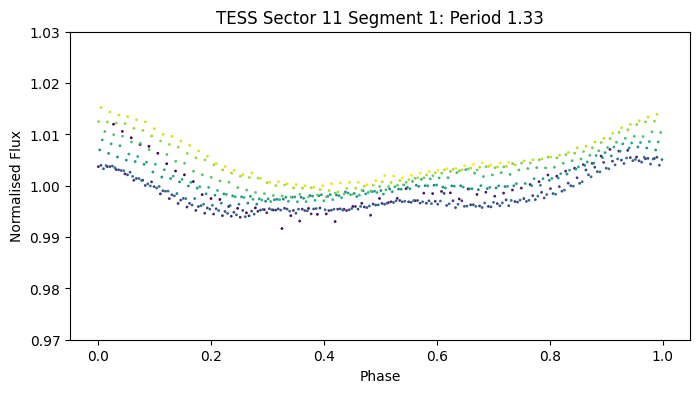

13.062352600011764


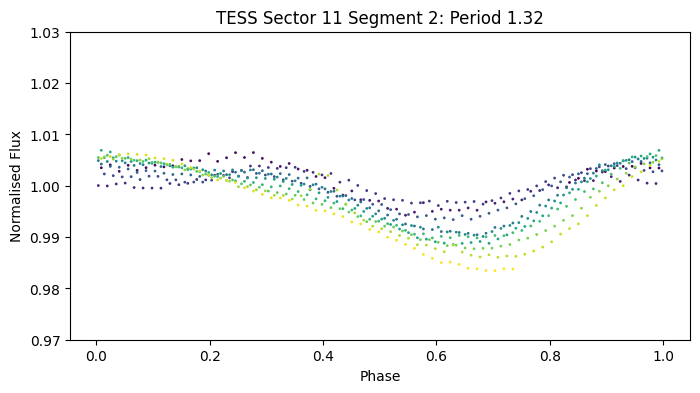

11.784972249825387


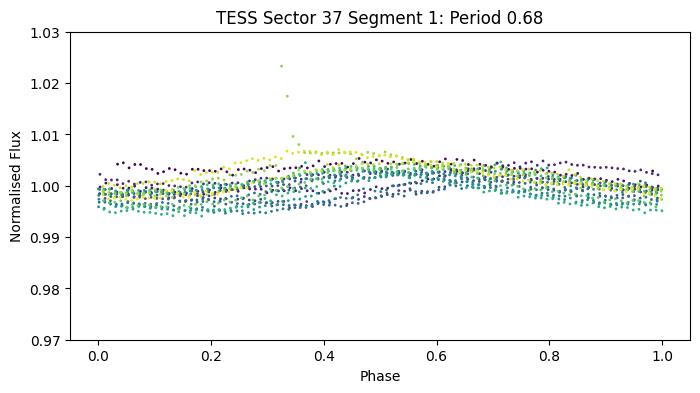

12.347330528129078


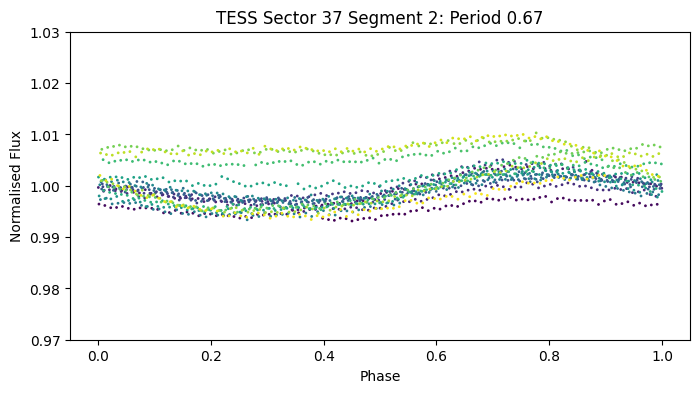

12.472169346406645


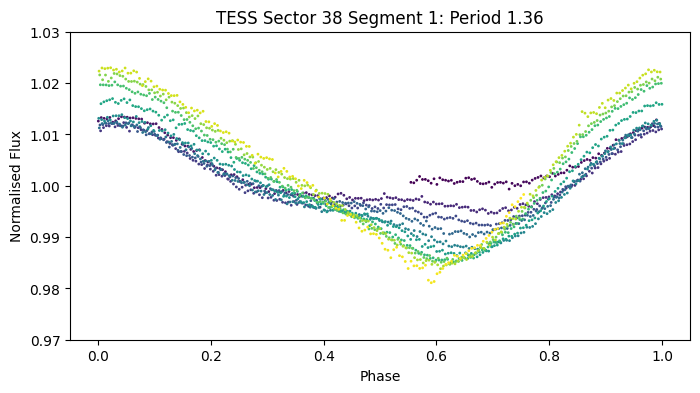

13.24282748910764


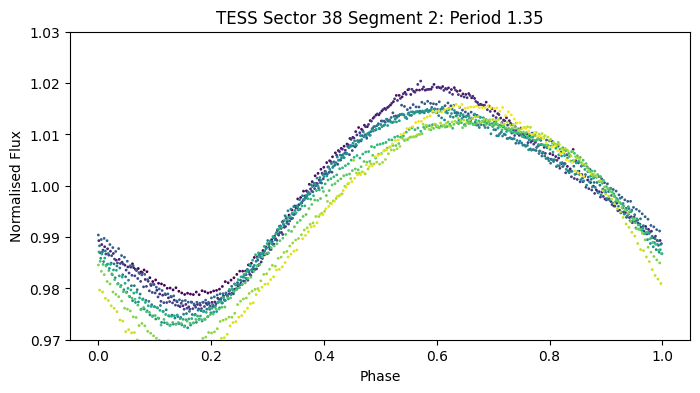

6.995509801098706


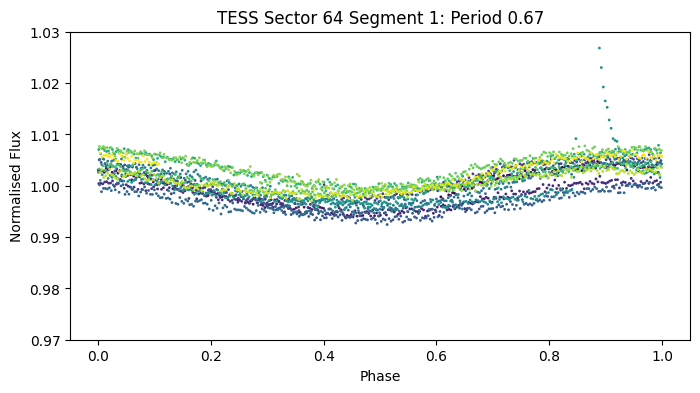

6.745463371768437


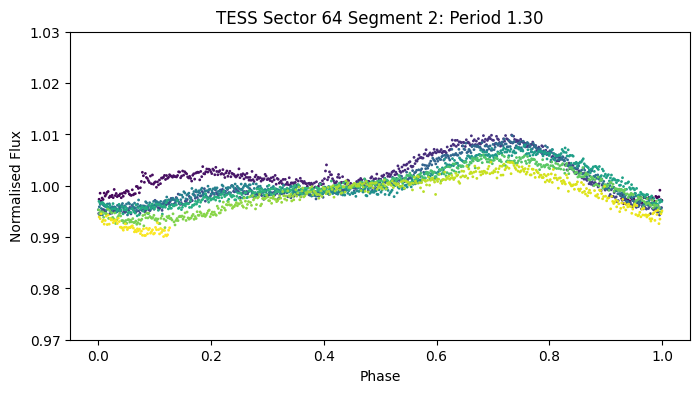

6.91902706431847


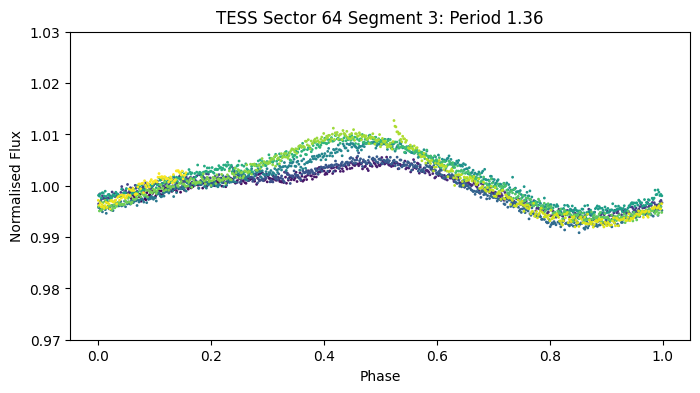

5.5925961588213795


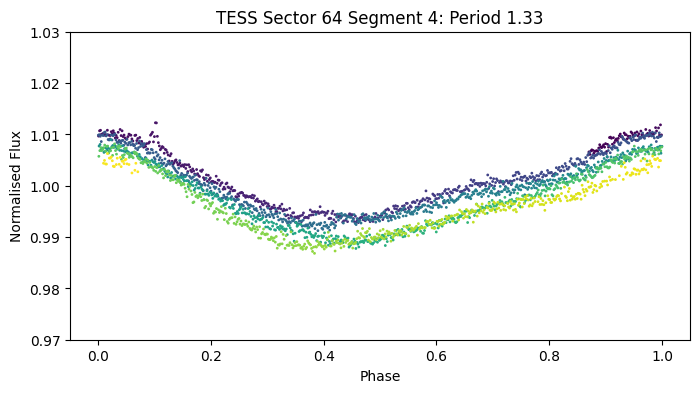

7.224491682826283


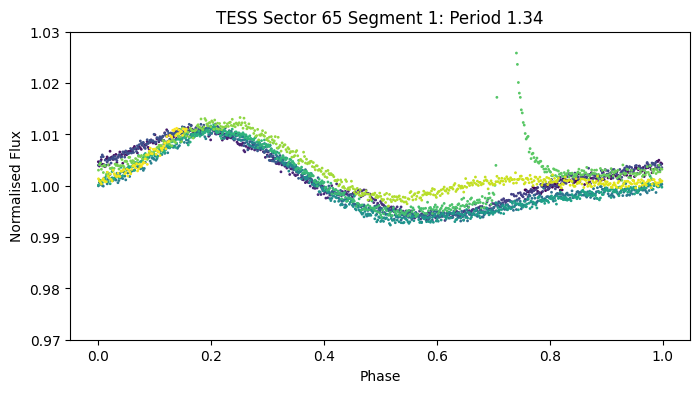

7.286943176871773


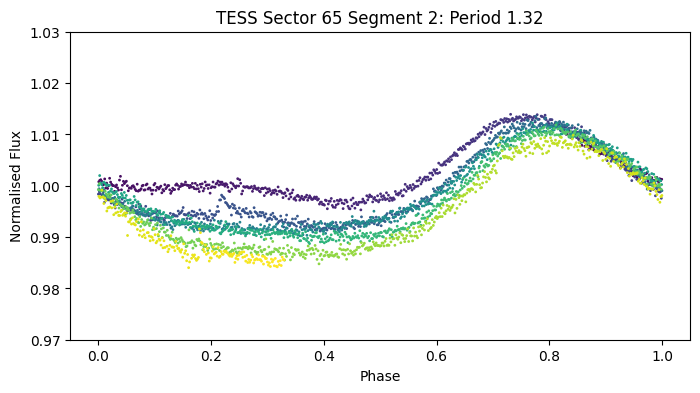

6.557739523417695


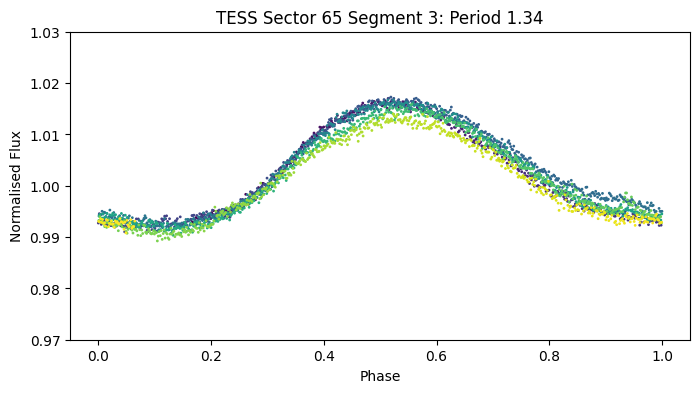

6.115585438607923


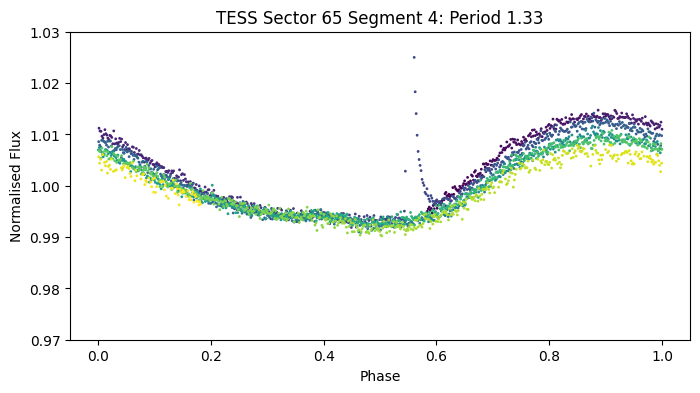

6.715274473832778


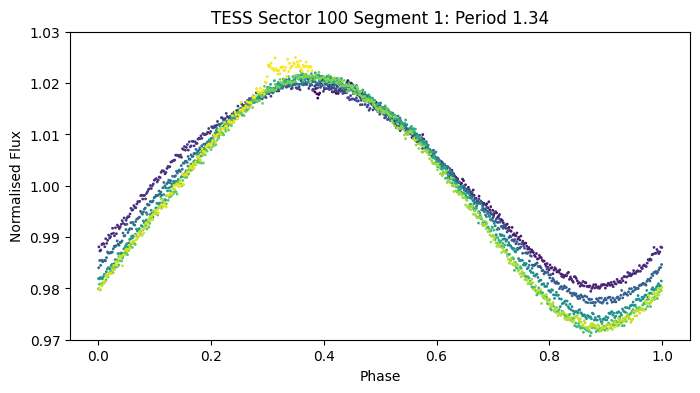

6.4027746794099585


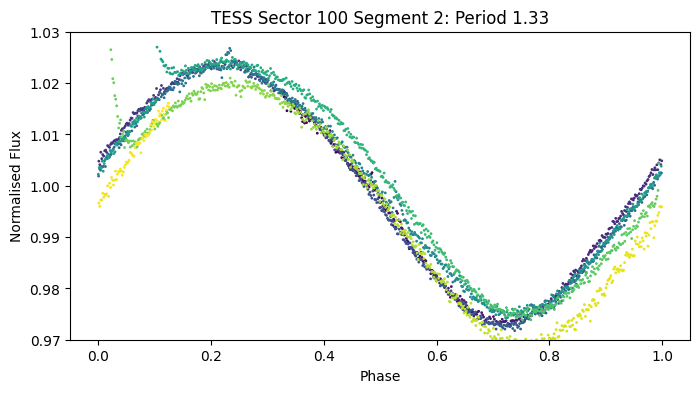

6.613422774679748


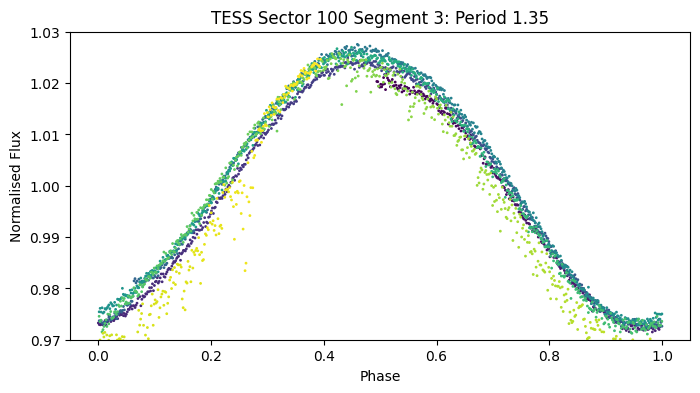

4.898145860635395


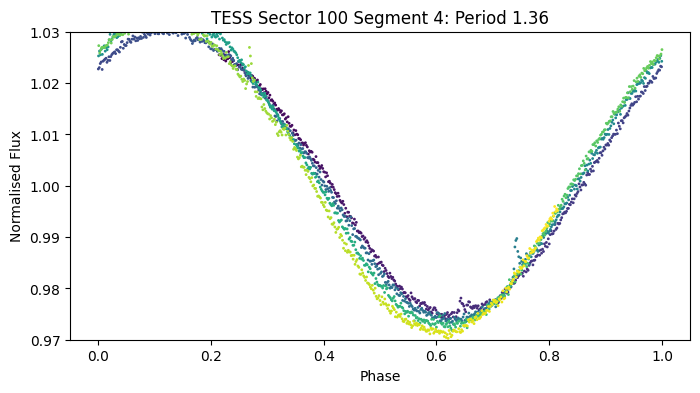

1.2013883278032154


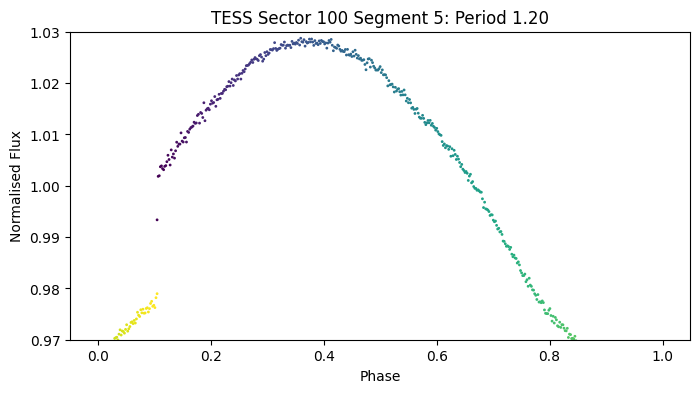

6.521189911966758


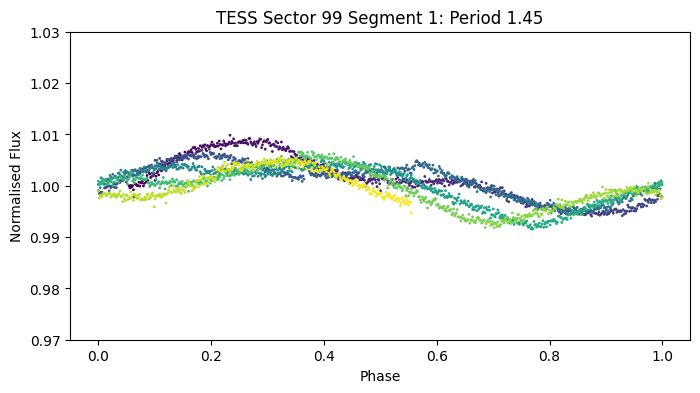

2.8635783896620524


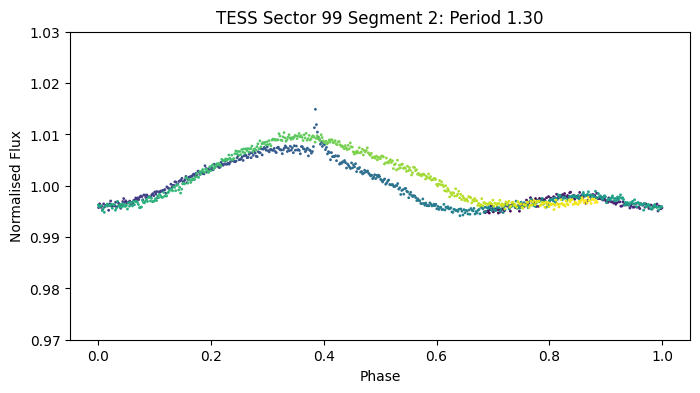

4.1761655074465125


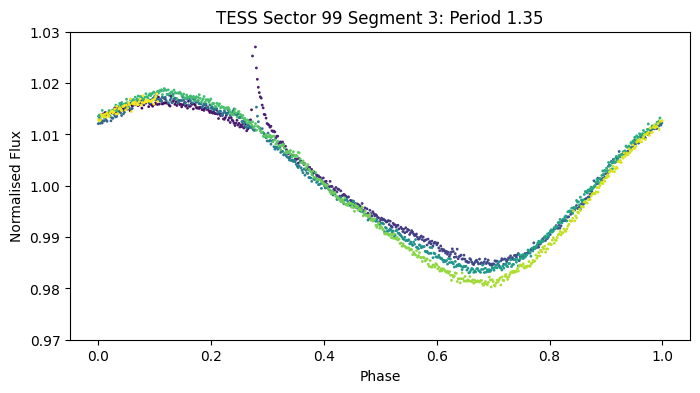

6.368279622669888


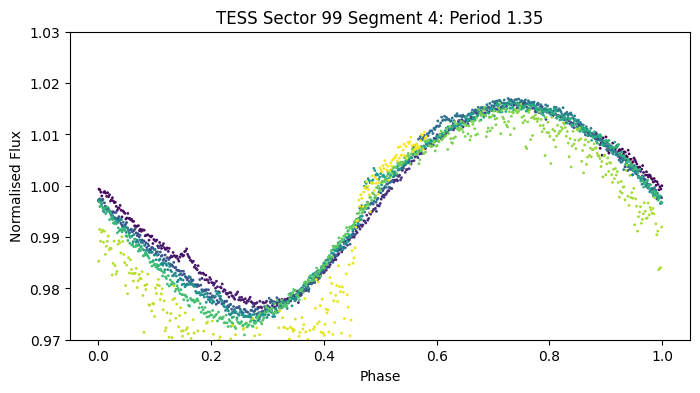

In [189]:
# Time to calculate periods!
periods = []

for lc_obj in lc_list:

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download()

    # Segment our lightcurves
    lc_segments = segment_lc(lc, cadence)

    # Now calculate periods/plot for each segment
    for i, segment in enumerate(lc_segments):

        period, phase = find_phase(segment)
        periods.append(period)
        print(max(segment.time.value) - min(segment.time.value))

        # Plot it
        plt.figure(figsize = (8,4))
        plt.scatter(phase, segment.flux.value, c = segment.time.value, cmap = 'viridis', s = 1)
        plt.xlabel('Phase')
        plt.ylabel('Normalised Flux')
        plt.title(f'{sector} Segment {i+1}: Period {period:.2f}')
        plt.ylim(0.97, 1.03)
        plt.show()
        plt.close()

In [190]:
periods

[np.float64(1.327322467041766),
 np.float64(1.3194295555567428),
 np.float64(0.6808108457394185),
 np.float64(0.6674232717907612),
 np.float64(1.3556705811311567),
 np.float64(1.3513089274599621),
 np.float64(0.6662390286760675),
 np.float64(1.2972044945708532),
 np.float64(1.356671973395779),
 np.float64(1.3315705140050909),
 np.float64(1.3378688301530162),
 np.float64(1.324898759431232),
 np.float64(1.3383141884525904),
 np.float64(1.3294750953495482),
 np.float64(1.343054894766556),
 np.float64(1.3339113915437413),
 np.float64(1.3496781172815808),
 np.float64(1.3605960723987212),
 np.float64(1.2013883278032154),
 np.float64(1.4491533137703898),
 np.float64(1.3016265407554783),
 np.float64(1.3471501636924241),
 np.float64(1.3549531112063582)]

This was largely successful bar for a few inconsistencies. With such small data volume, we can just re-compute these manually real quick.

We need to recompute both segments for index 1 and the first segment for index 3

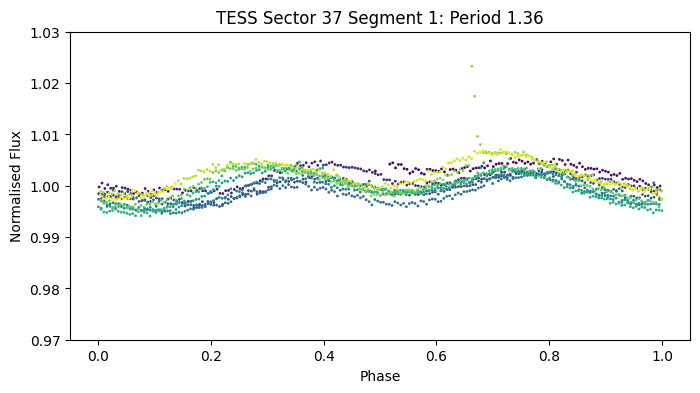

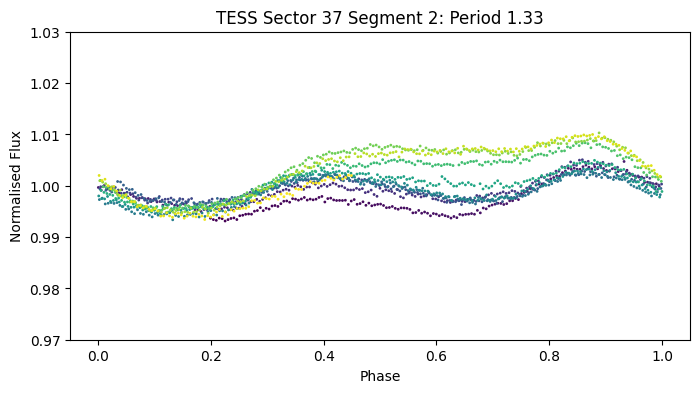

In [191]:
lc_obj = lc_list[1]

# Sector name
sector = lc_obj.mission[0]

# Find the cadence
cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

# Go from list --> LC
lc = lc_obj.download()

# Segment our lightcurves
lc_segments = segment_lc(lc, cadence)

# Now calculate periods/plot for each segment
for i, segment in enumerate(lc_segments):

    period, phase = find_phase(segment)
    period *= 2
    phase = (segment.time.value % period) / period
    periods[2+i] = period

    # Plot it
    plt.figure(figsize = (8,4))
    plt.scatter(phase, segment.flux.value, c = segment.time.value, cmap = 'viridis', s = 1)
    plt.xlabel('Phase')
    plt.ylabel('Normalised Flux')
    plt.title(f'{sector} Segment {i+1}: Period {period:.2f}')
    plt.ylim(0.97, 1.03)
    plt.show()
    plt.close()

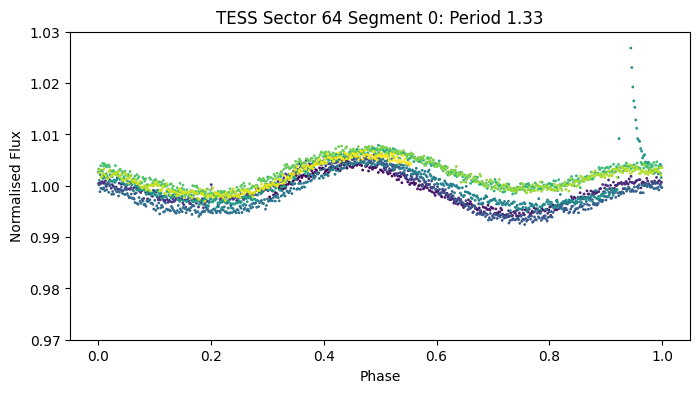

In [192]:
lc_obj = lc_list[3]

# Sector name
sector = lc_obj.mission[0]

# Find the cadence
cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

# Go from list --> LC
lc = lc_obj.download()

# Segment our lightcurves
lc_segments = segment_lc(lc, cadence)

segment = lc_segments[0]

period, phase = find_phase(segment)
period *= 2
phase = (segment.time.value % period) / period
periods[6] = period

# Plot it
plt.figure(figsize = (8,4))
plt.scatter(phase, segment.flux.value, c = segment.time.value, cmap = 'viridis', s = 1)
plt.xlabel('Phase')
plt.ylabel('Normalised Flux')
plt.title(f'{sector} Segment {0}: Period {period:.2f}')
plt.ylim(0.97, 1.03)
plt.show()
plt.close()

My guess is that these half periods can be explained by some antipodal starspots???

Now that we have a list of periods though, we can actually get an error!

In [193]:
print(f"Period = {np.mean(periods):.2f} ± {np.std(periods):.2f} days")

Period = 1.34 ± 0.04 days


In [198]:
np.mean(periods)

np.float64(1.3365301570512478)

# TYC 8927

In theory we can just plug and play with this star now, using the same code as above:

In [184]:
lc_list_tyc = lk.search_lightcurve('TYC 8927-1888-1', author='QLP')

In [185]:
lc_list_tyc

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 09,2019,QLP,1800,356768629,0.0
1,TESS Sector 10,2019,QLP,1800,356768629,0.0
2,TESS Sector 35,2021,QLP,600,356768629,0.0
3,TESS Sector 36,2021,QLP,600,356768629,0.0
4,TESS Sector 37,2021,QLP,600,356768629,0.0
5,TESS Sector 62,2023,QLP,200,356768629,0.0
6,TESS Sector 63,2023,QLP,200,356768629,0.0
7,TESS Sector 64,2023,QLP,200,356768629,0.0
8,TESS Sector 89,2025,QLP,200,356768629,0.0


In [188]:
lc = lc_list_tyc[5].download()
lc_all = lc_list_tyc.download_all().stitch()

DEFINE A T0 HERE SO WE CAN FIX THE ROTATIONAL PHASE OF OUR STAR

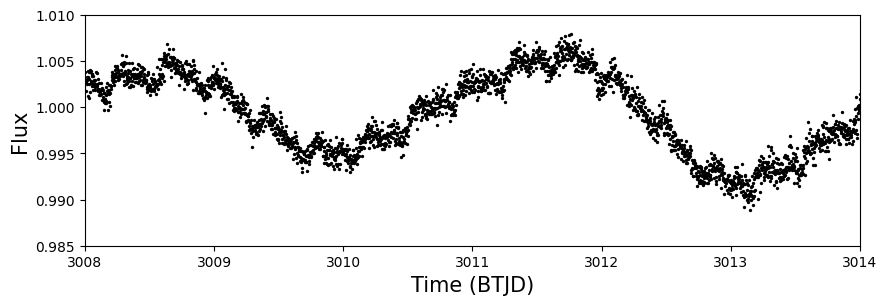

In [194]:
plt.figure(figsize = (10,3))
plt.scatter(lc.time.value, lc.flux.value, s = 2, c = 'black')
plt.ylim(0.985,1.01)
plt.xlim(3008,3014)
plt.xlabel('Time (BTJD)', fontsize=15)
plt.ylabel('Flux',fontsize=15)
plt.savefig('thesis_figs/tyc8927-tess.pdf', dpi=300, bbox_inches='tight')
# plt.title('TYC 8927 TESS Sector 62',fontsize=20)

In [195]:
t0 = lc.time.value[0]

In [196]:
freq, amp = calc_lomb_scargle(lc_all.time.value, lc_all.flux.value)

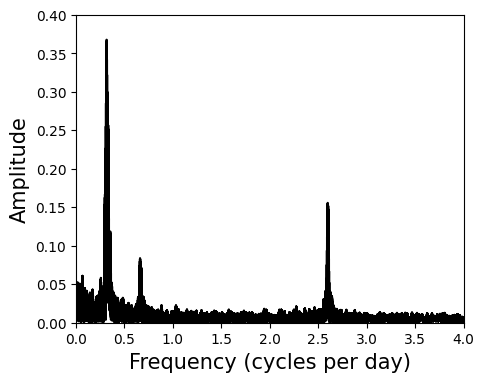

In [201]:
plt.figure(figsize = (5,4))
plt.plot(freq,amp, c = 'black')
plt.xlim(0,4)
plt.ylim(0,0.4)
plt.xlabel('Frequency (cycles per day)', fontsize=15)
plt.ylabel('Amplitude', fontsize=15)
plt.savefig('thesis_figs/tyc8927-periodogram.pdf', dpi=300, bbox_inches='tight')

# plt.title('Periodogram - all TESS data', fontsize=20)

In [77]:
# Time to calculate periods!
periods_tyc = []

for lc_obj in lc_list_tyc:

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download()

    # Segment our lightcurves
    lc_segments = segment_lc(lc, cadence)

    # Now calculate periods/plot for each segment
    for i, segment in enumerate(lc_segments):
        print(max(segment.time.value) - min(segment.time.value))
        
        period, phase = find_phase(segment)
        periods_tyc.append(period)

        # Plot it
        plt.figure(figsize = (8,4))
        plt.scatter(phase, segment.flux.value, c = segment.time.value, cmap = 'viridis', s = 1)
        plt.xlabel('Phase')
        plt.ylabel('Normalised Flux')
        plt.title(f'{sector} Segment {i+1}: Period {period:.2f}')
        plt.ylim(0.97, 1.03)
        plt.show()
        plt.close()

NameError: name 'segment_lc' is not defined

Unfortunately it can never be that simple. The majority of the time, we pick up a signal of ~3 days, but sometimes we pick up a signal of ~0.4 days. Since this system is almost definitely a binary, these are likely the rotation period and the orbital period of the star. My proposed solution is therefore to try and phase fold to both of these periods and see if it lines up still. To do this fitting, let's use sector by sector data rather than segment by segment data, since some of our segments were only 2 periods long.


In [29]:
def find_phase_restricted_period(lc, t0, pmin = None, pmax = None):

    # Perform a Lomb Scargle
    freq, amp = calc_lomb_scargle(lc.time.value, lc.flux.value)

    # Take the peak to be the periodicity
    if pmin == None:
        highest_power = np.argmax(amp)
        period = 1 / (freq[highest_power])

    else:
        freq_max = 1 / pmin
        freq_min = 1 / pmax
        freq_bounds = (freq > freq_min) & (freq < freq_max)
        
        freq = freq[freq_bounds]
        amp = amp[freq_bounds]

        highest_power = np.argmax(amp)
        period = 1 / (freq[highest_power])
    
    phase = ((lc.time.value - t0) / period)%1

    return period, phase

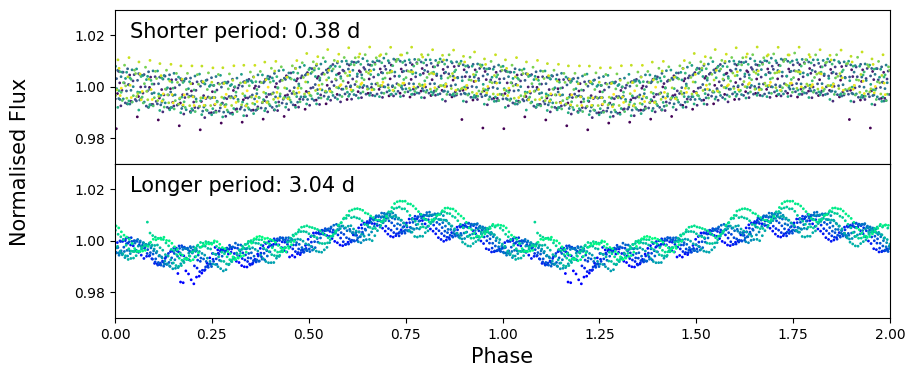

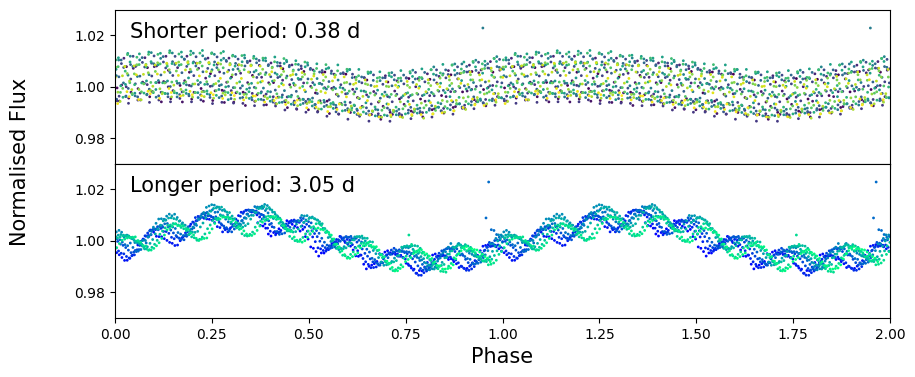

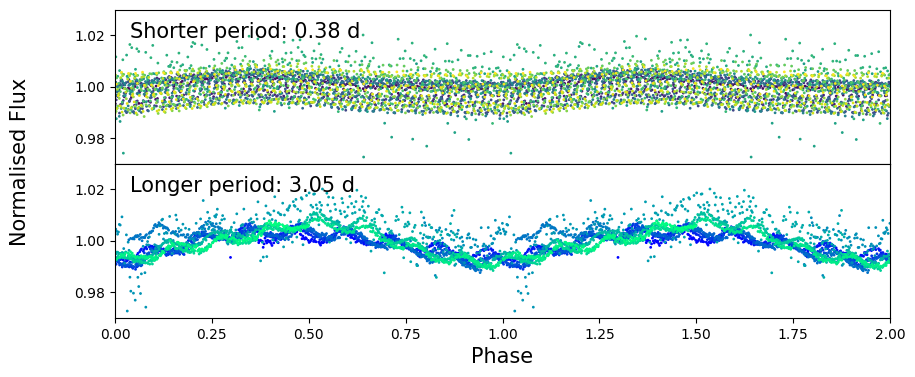

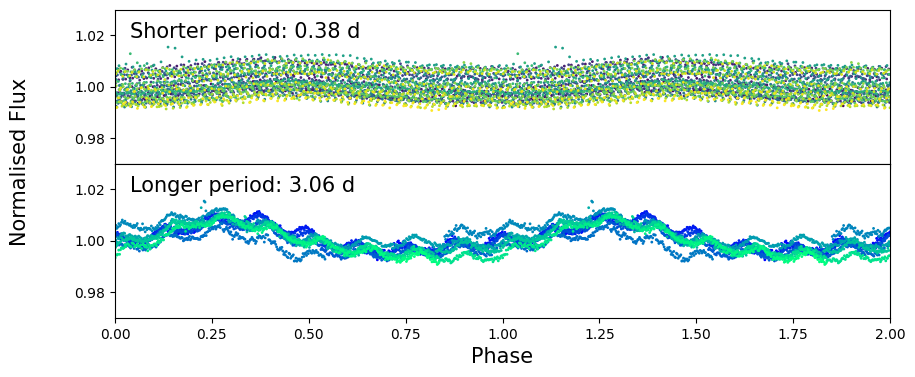

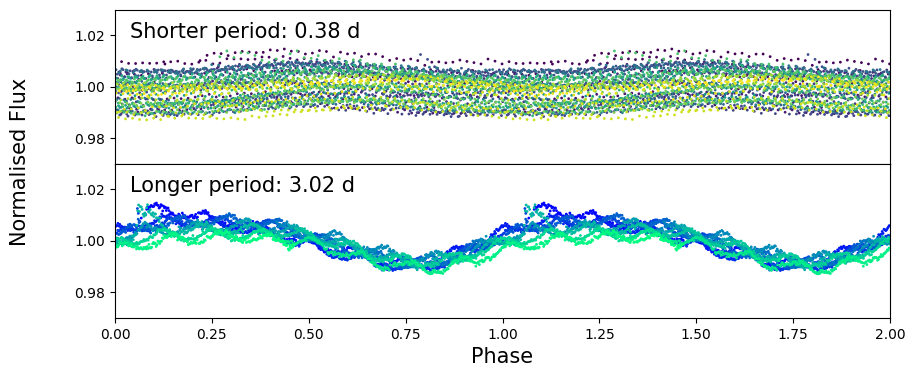

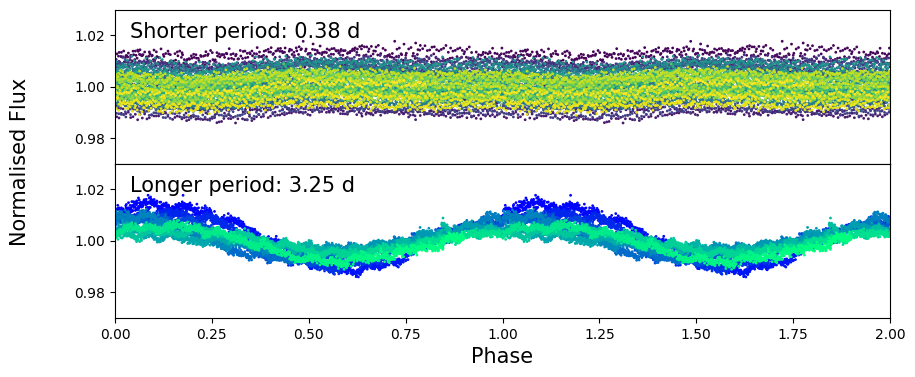

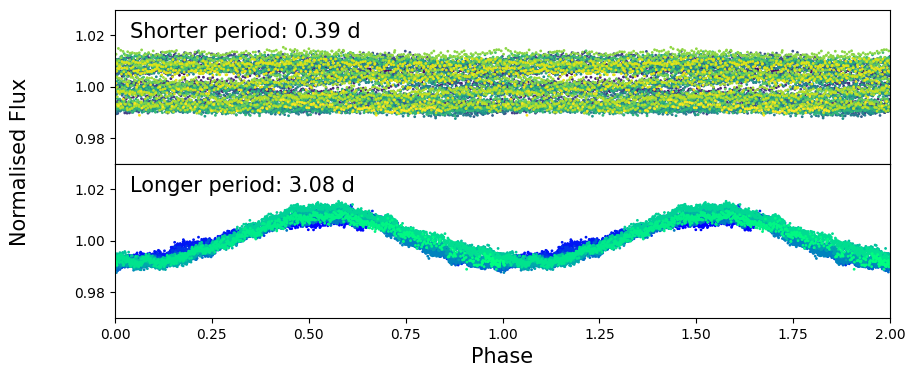

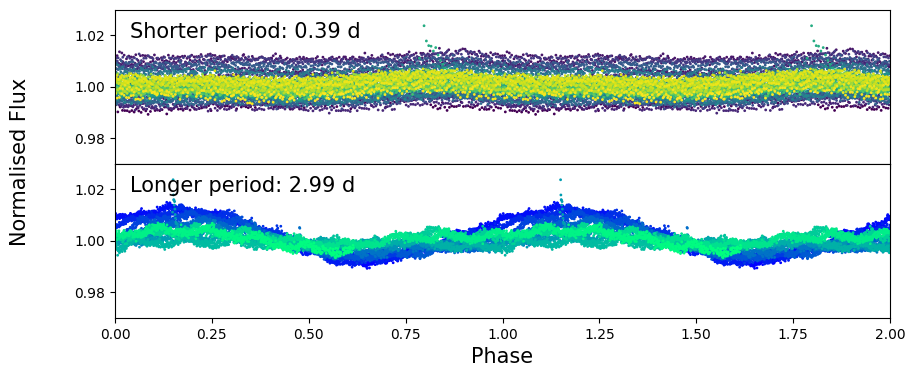

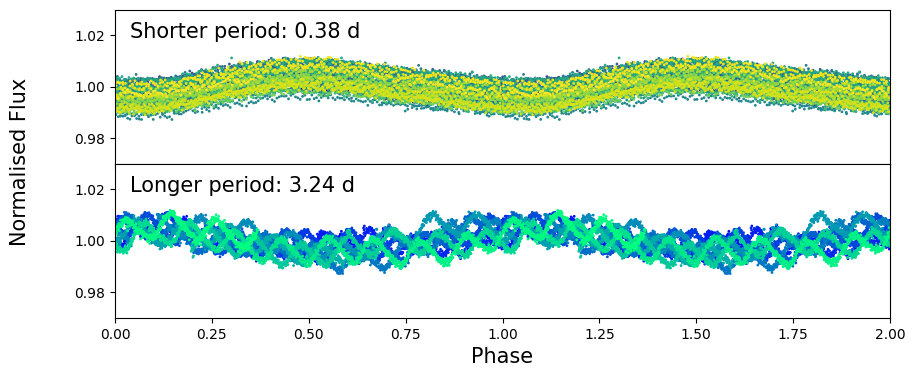

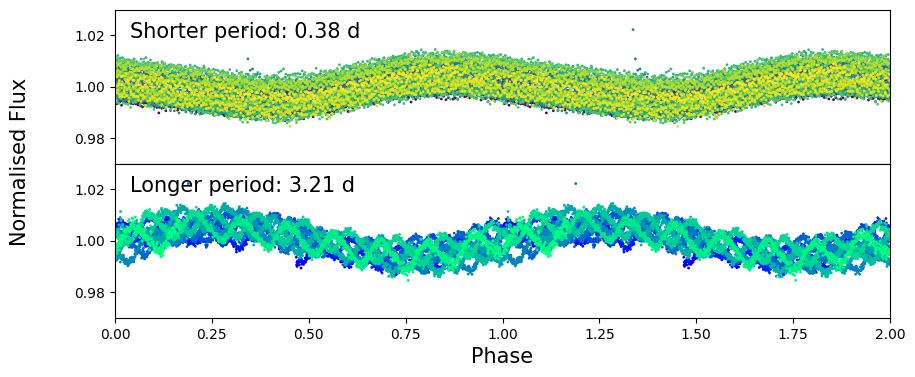

In [216]:
# Time to calculate periods!
p_rot, p_bin = [], []

for i, lc_obj in enumerate(lc_list_tyc):

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download()
  
    period_r, phase_r = find_phase_restricted_period(lc, t0=t0, pmin=0.2, pmax=0.6)
    period_b, phase_b = find_phase_restricted_period(lc, t0=t0, pmin=2.5, pmax=3.5)
    p_rot.append(period_r)
    p_bin.append(period_b)

    # Plot both periods as vertically stacked subplots
    fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
    
    # Rotation period
    axes[0].scatter(
        np.concatenate([phase_r, phase_r + 1]),
        np.concatenate([lc.flux.value, lc.flux.value]),
        c=np.tile(lc.time.value, 2),
        cmap='viridis',
        s=1
    )
    # axes[0].set_ylabel('Normalised Flux')
    axes[0].set_ylim(0.97, 1.03)
    
    # Title inside subplot
    axes[0].text(
        0.02, 0.92, f'Shorter period: {period_r:.2f} d',
        transform=axes[0].transAxes,
        ha='left', va='top', fontsize= 15
    )
    
    # Binary period
    axes[1].scatter(
        np.concatenate([phase_b, phase_b + 1]),
        np.concatenate([lc.flux.value, lc.flux.value]),
        c=np.tile(lc.time.value, 2),
        cmap='winter',
        s=1
    )
    # axes[1].set_ylabel('Normalised Flux')
    axes[1].set_ylim(0.97, 1.03)
    
    # Title inside subplot
    axes[1].text(
        0.02, 0.92, f'Longer period: {period_b:.2f} d',
        transform=axes[1].transAxes,
        ha='left', va='top', fontsize=15
    )
    
    axes[1].set_xlabel('Phase', fontsize=15)
    axes[1].set_xlim(0, 2)
    
    # Remove gap between subplots
    fig.subplots_adjust(hspace=0)
    fig.supylabel('Normalised Flux', fontsize=15)

    if i == 8:
        plt.savefig('thesis_figs/tyc8927-phase-lc.pdf', dpi=300, bbox_inches='tight')

    
    plt.show()
    plt.close()

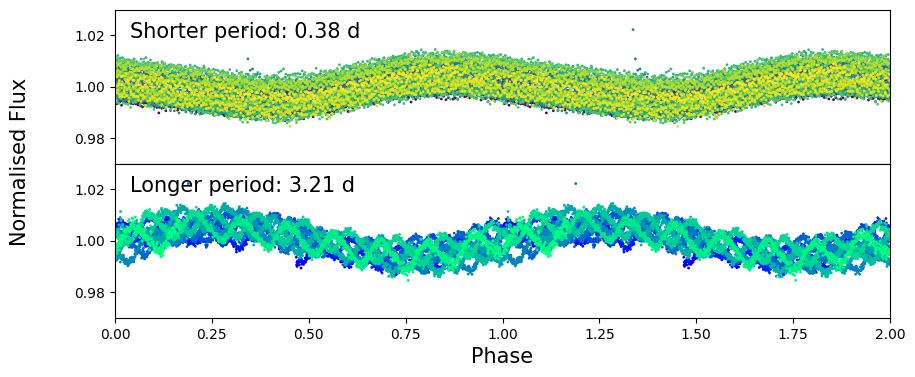

In [213]:
# Plot both periods as vertically stacked subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)

# Rotation period
axes[0].scatter(
    np.concatenate([phase_r, phase_r + 1]),
    np.concatenate([lc.flux.value, lc.flux.value]),
    c=np.tile(lc.time.value, 2),
    cmap='viridis',
    s=1
)
# axes[0].set_ylabel('Normalised Flux')
axes[0].set_ylim(0.97, 1.03)

# Title inside subplot
axes[0].text(
    0.02, 0.92, f'Shorter period: {period_r:.2f} d',
    transform=axes[0].transAxes,
    ha='left', va='top', fontsize= 15
)

# Binary period
axes[1].scatter(
    np.concatenate([phase_b, phase_b + 1]),
    np.concatenate([lc.flux.value, lc.flux.value]),
    c=np.tile(lc.time.value, 2),
    cmap='winter',
    s=1
)
# axes[1].set_ylabel('Normalised Flux')
axes[1].set_ylim(0.97, 1.03)

# Title inside subplot
axes[1].text(
    0.02, 0.92, f'Longer period: {period_b:.2f} d',
    transform=axes[1].transAxes,
    ha='left', va='top', fontsize=15
)

axes[1].set_xlabel('Phase', fontsize=15)
axes[1].set_xlim(0, 2)

# Remove gap between subplots
fig.subplots_adjust(hspace=0)
fig.supylabel('Normalised Flux', fontsize=15)

plt.show()
plt.close()

In [80]:
print(f"Rotation Period = {np.mean(p_rot):.3f} ± {np.std(p_rot):.3f} days")

Rotation Period = 0.385 ± 0.001 days


In [81]:
print(f"Binary Period = {np.mean(p_bin):.2f} ± {np.std(p_bin):.2f} days")

Binary Period = 3.10 ± 0.09 days


There is also another possible period at a frequency ~5.2. Let's fit to this too, and check if it is a harmonic of the other periods we found.

(3.5, 7.0)

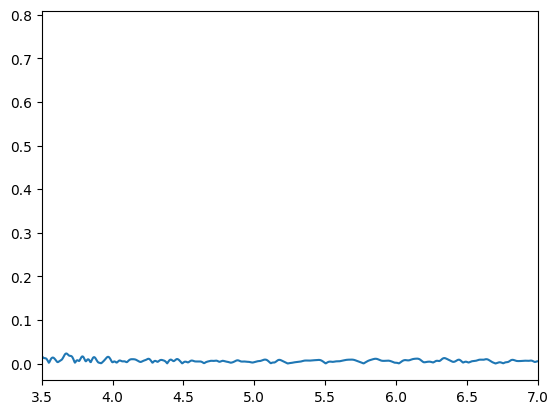

In [82]:
plt.plot(freq, amp)
plt.xlim(3.5,7)

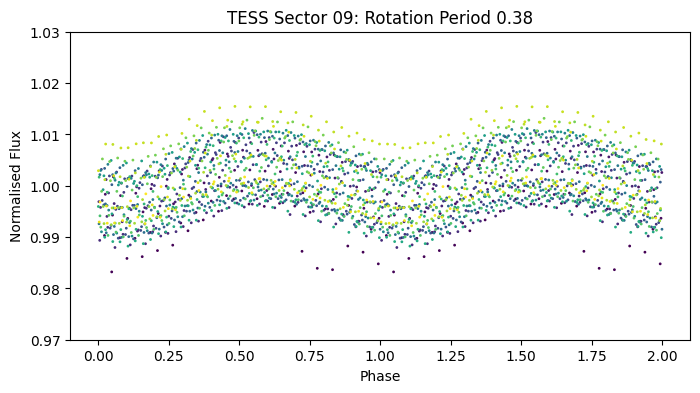

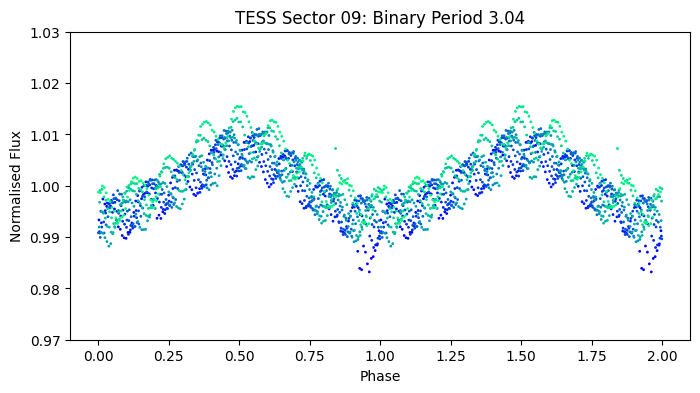

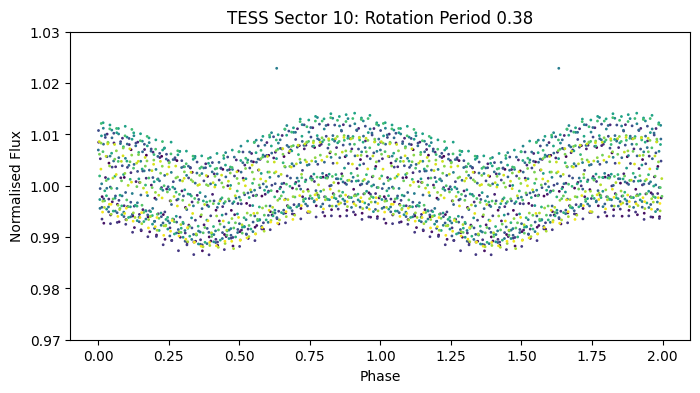

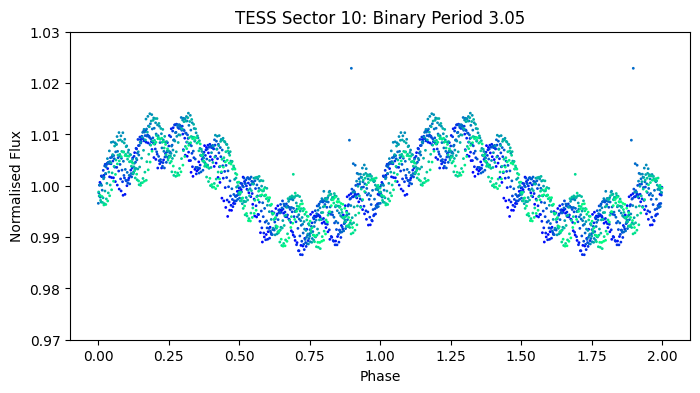

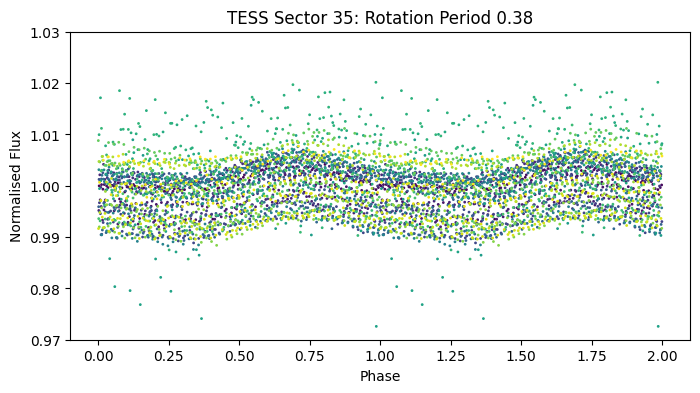

...

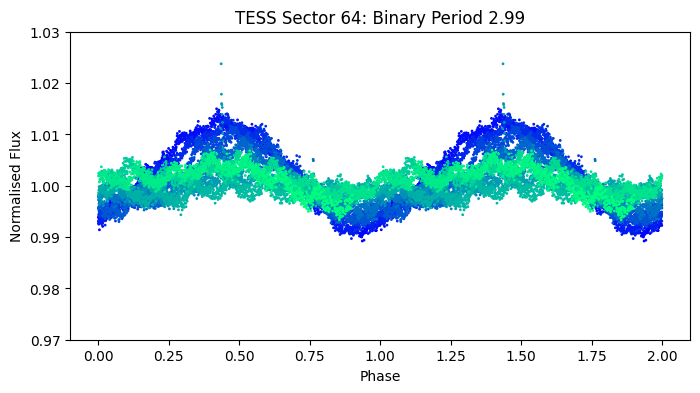

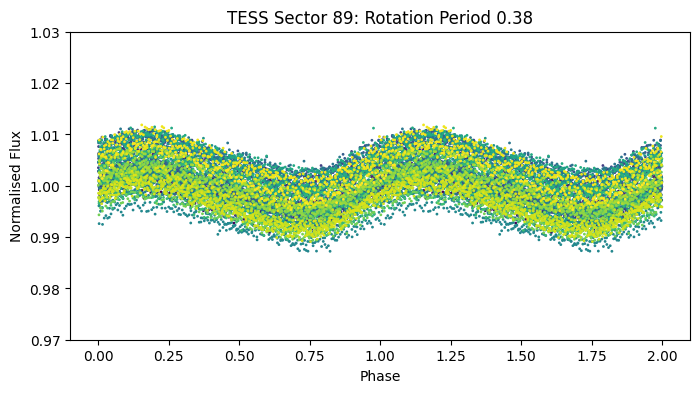

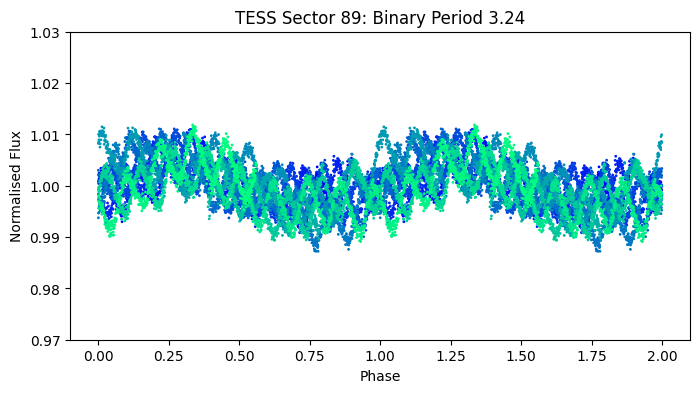

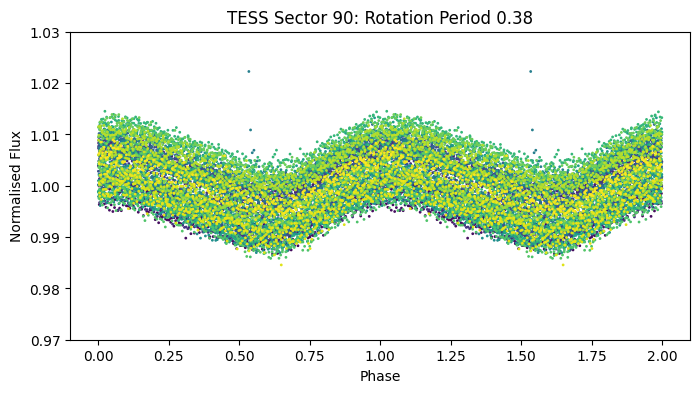

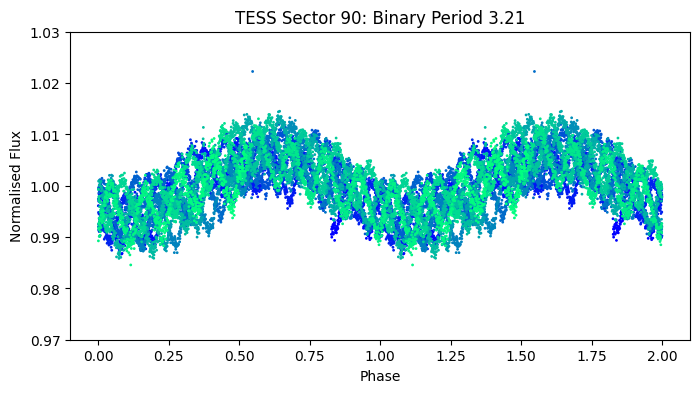

In [83]:
# Time to calculate periods!
p1, p2, p3 = [], [], []

for lc_obj in lc_list_tyc:

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download()
  
    period1, phase1 = find_phase_restricted_period(lc, t0=t0, pmin=0.2, pmax=0.6)
    period2, phase2 = find_phase_restricted_period(lc, t0=t0, pmin=2.5, pmax=3.5)
    # period3, phase3 = find_phase_restricted_period(lc, pmin=0.15, pmax=0.25)
    
    p1.append(period1)
    p2.append(period2)
    # p3.append(period3)

    # Stack 2 on top of eachother to make the pattern more clear
    phase1 = np.concatenate([phase1, phase1 + 1])
    phase2 = np.concatenate([phase2, phase2 + 1])
    # phase3 = np.concatenate([phase3, phase3 + 1])
    flux = np.concatenate([lc.flux.value, lc.flux.value])
    time = np.concatenate([lc.time.value, lc.time.value])

    # Plot it
    plt.figure(figsize = (8,4))
    plt.scatter(phase1, flux, c = time, cmap = 'viridis', s = 1)
    plt.xlabel('Phase')
    plt.ylabel('Normalised Flux')
    plt.title(f'{sector}: Rotation Period {period1:.2f}')
    plt.ylim(0.97, 1.03)
    plt.show()
    plt.close()

    plt.figure(figsize = (8,4))
    plt.scatter(phase2, flux, c = time, cmap = 'winter', s = 1)
    plt.xlabel('Phase')
    plt.ylabel('Normalised Flux')
    plt.title(f'{sector}: Binary Period {period2:.2f}')
    plt.ylim(0.97, 1.03)
    plt.show()
    plt.close()

    # plt.figure(figsize = (8,4))
    # plt.scatter(phase3, flux, c = time, cmap = 'plasma', s = 1)
    # plt.xlabel('Phase')
    # plt.ylabel('Normalised Flux')
    # plt.title(f'{sector}: Binary Period {period3:.2f}')
    # plt.ylim(0.97, 1.03)
    # plt.show()
    # plt.close()

In [50]:
np.mean(p3)

np.float64(0.1890749508368699)

In [51]:
np.mean(p2)

np.float64(3.097892509945368)

In [53]:
np.mean(p1) / np.mean(p3)

np.float64(2.0336895487552202)

Based on the above, I am fairly certain this is just a harmonic of our 0.4 day period.

# Redoing HD 104919

Let's apply what we did to TYC 8927 to HD 104919 again:

In [130]:
lc_list = lk.search_lightcurve('HD 104919', author='QLP')

In [131]:
lc = lc_list[0].download()

In [132]:
t0 = lc.time.value[0]

In [133]:
freq, amp = calc_lomb_scargle(lc.time.value, lc.flux.value)

(1.5, 3.0)

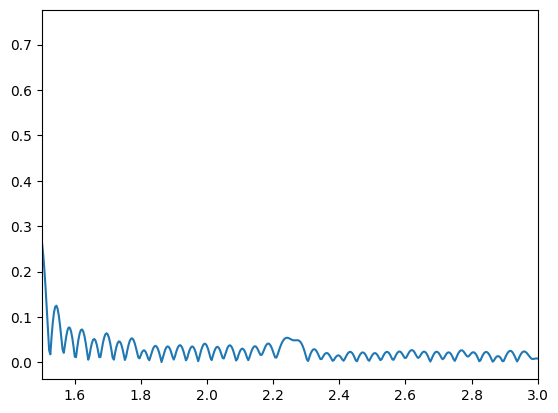

In [134]:
plt.plot(freq, amp)
plt.xlim(1.5,3)

Visually, the next 2 humps seem to be harmonics, but it isn't too much work to check it out ourselves.

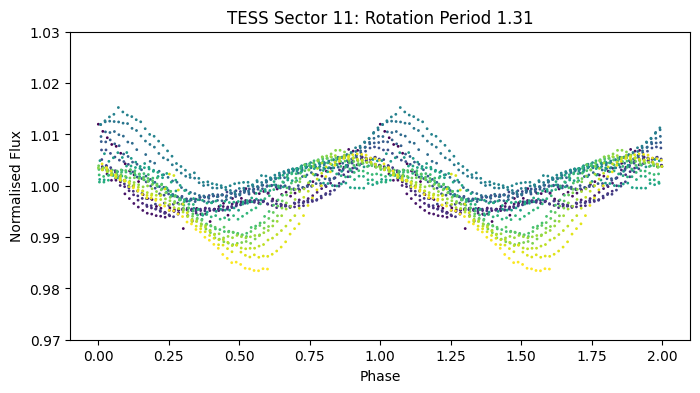

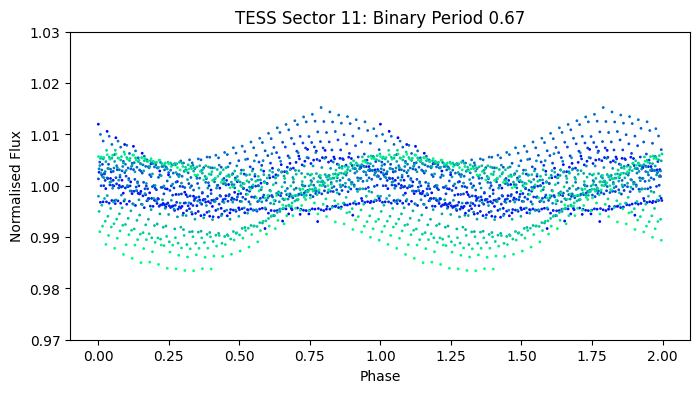

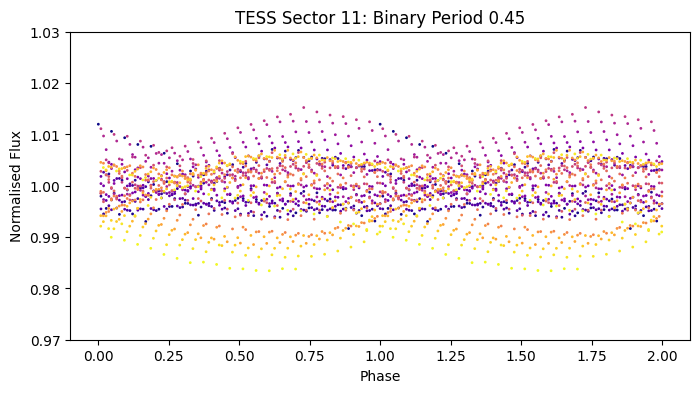

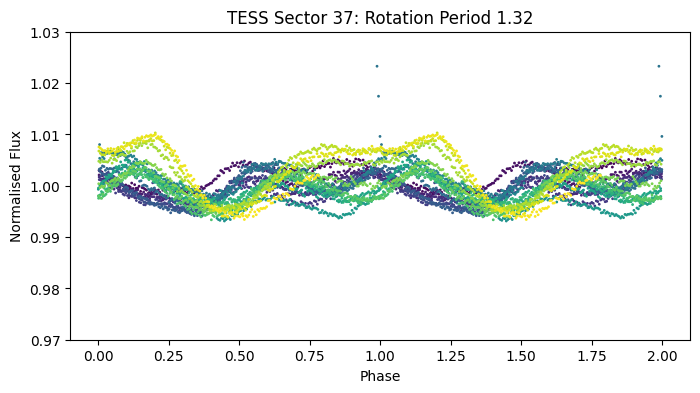

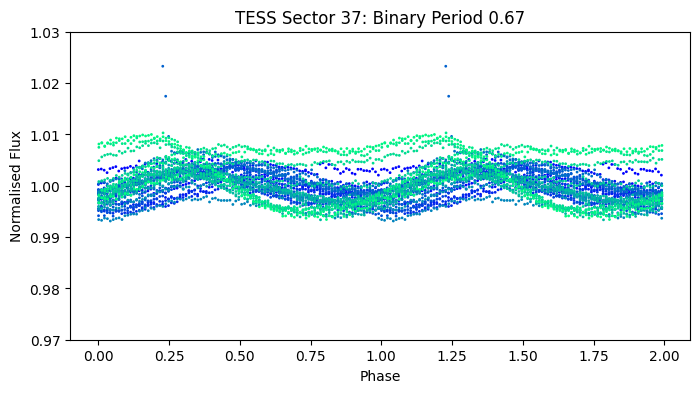

...

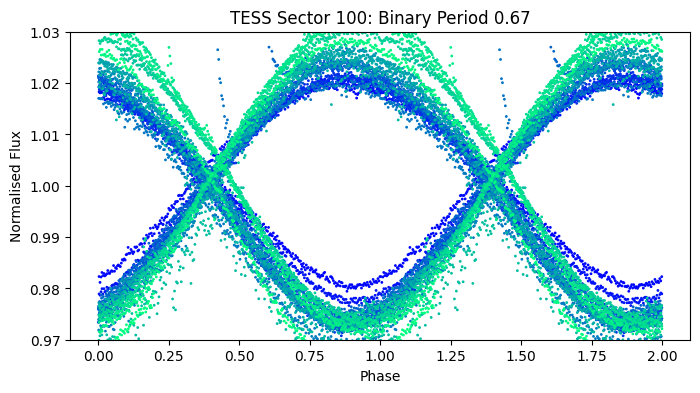

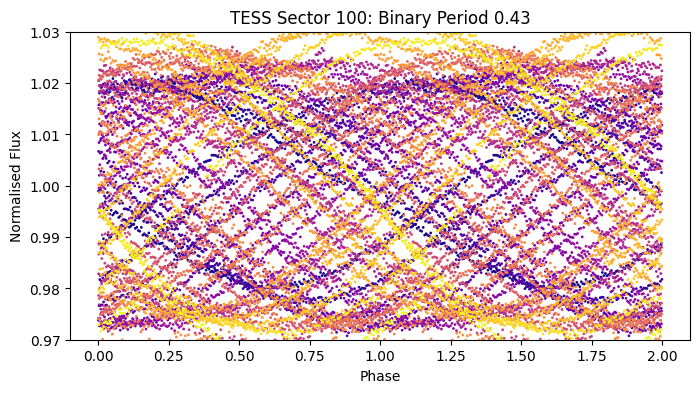

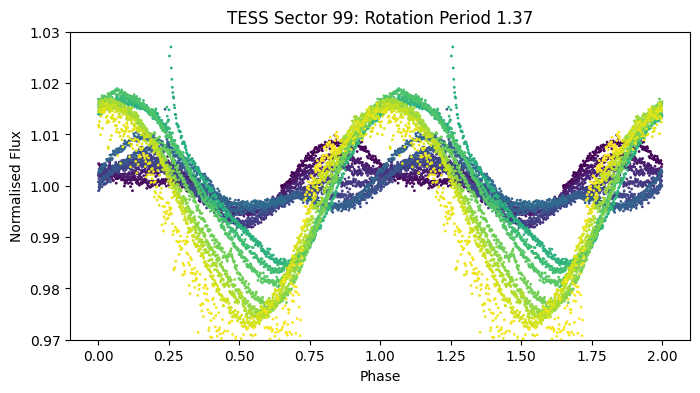

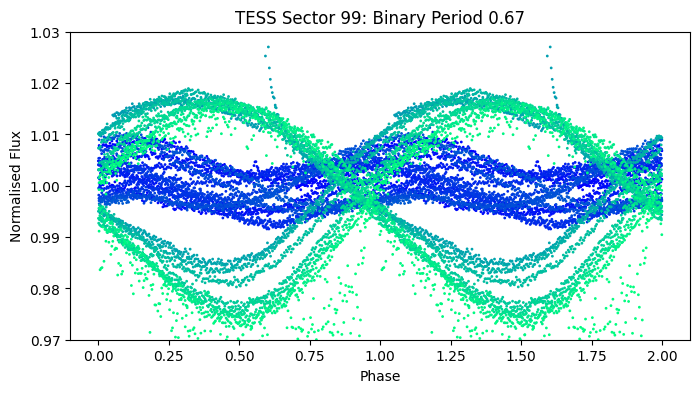

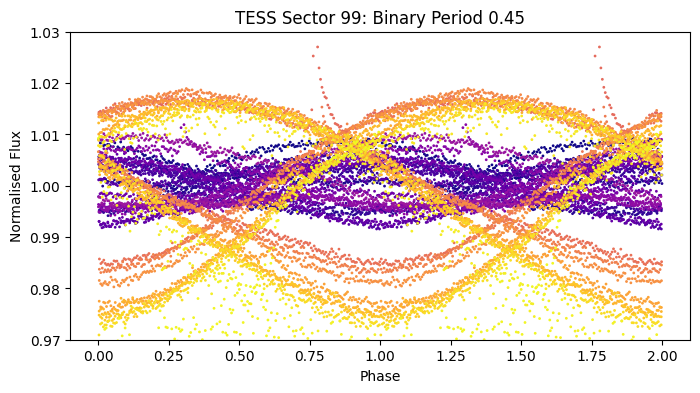

In [92]:
# Time to calculate periods!
p4, p5, p6 = [], [], []

for lc_obj in lc_list:

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download()
  
    period4, phase4 = find_phase_restricted_period(lc, t0=t0, pmin=1.25, pmax=1.45)
    period5, phase5 = find_phase_restricted_period(lc, t0=t0, pmin=0.6, pmax=0.72)
    period6, phase6 = find_phase_restricted_period(lc, t0=t0, pmin=0.42, pmax=0.48)
    
    p4.append(period4)
    p5.append(period5)
    p6.append(period6)

    # Stack 2 on top of eachother to make the pattern more clear
    phase4 = np.concatenate([phase4, phase4 + 1])
    phase5 = np.concatenate([phase5, phase5 + 1])
    phase6 = np.concatenate([phase6, phase6 + 1])
    flux = np.concatenate([lc.flux.value, lc.flux.value])
    time = np.concatenate([lc.time.value, lc.time.value])

    # Plot it
    plt.figure(figsize = (8,4))
    plt.scatter(phase4, flux, c = time, cmap = 'viridis', s = 1)
    plt.xlabel('Phase')
    plt.ylabel('Normalised Flux')
    plt.title(f'{sector}: Rotation Period {period4:.2f}')
    plt.ylim(0.97, 1.03)
    plt.show()
    plt.close()

    plt.figure(figsize = (8,4))
    plt.scatter(phase5, flux, c = time, cmap = 'winter', s = 1)
    plt.xlabel('Phase')
    plt.ylabel('Normalised Flux')
    plt.title(f'{sector}: Binary Period {period5:.2f}')
    plt.ylim(0.97, 1.03)
    plt.show()
    plt.close()

    plt.figure(figsize = (8,4))
    plt.scatter(phase6, flux, c = time, cmap = 'plasma', s = 1)
    plt.xlabel('Phase')
    plt.ylabel('Normalised Flux')
    plt.title(f'{sector}: Binary Period {period6:.2f}')
    plt.ylim(0.97, 1.03)
    plt.show()
    plt.close()

In [96]:
np.mean(p4) / np.mean(p5)

np.float64(2.001247157459649)

In [97]:
np.nanmean(p4) / np.nanmean(p6)

np.float64(3.036226033729381)

i.e. our 2nd and 3rd harmonics, which are in descending strength.

Trying again with segmenting to make our LCs look better, and moving back to a single period:

0


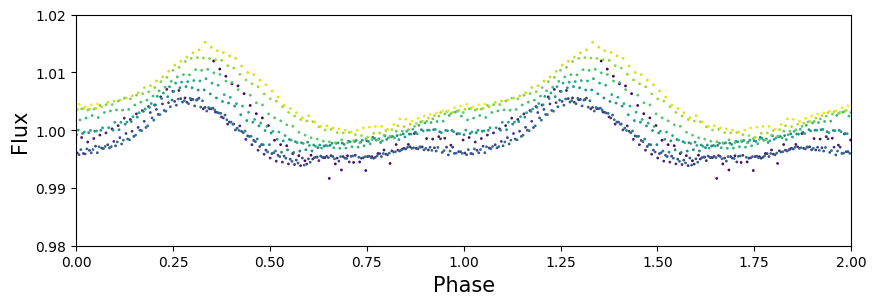

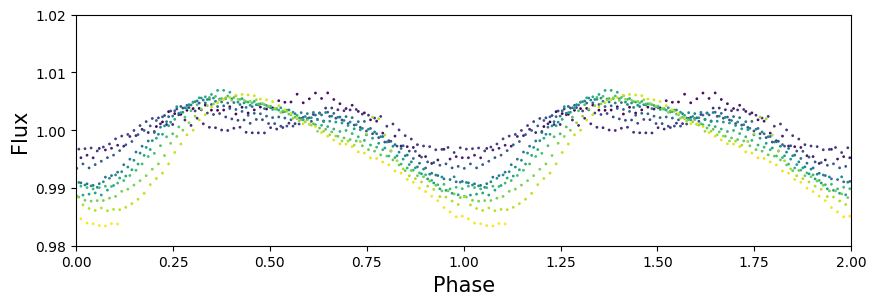

1


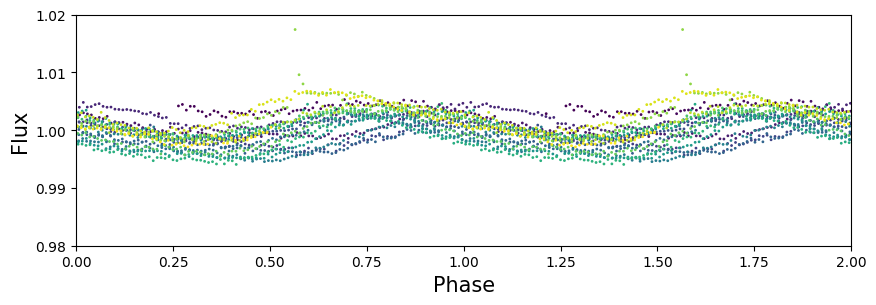

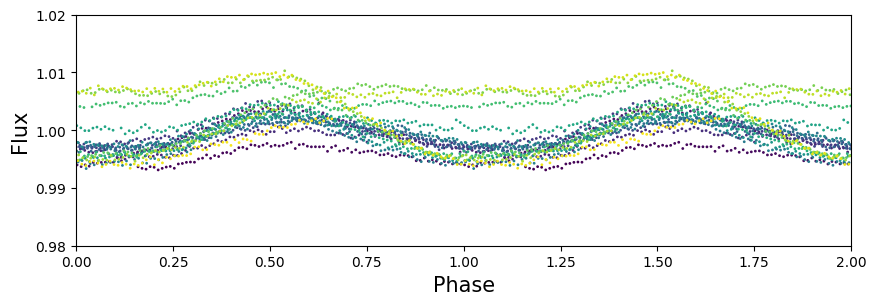

2


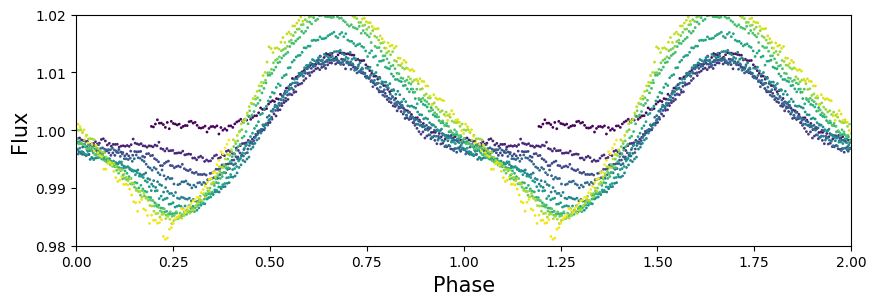

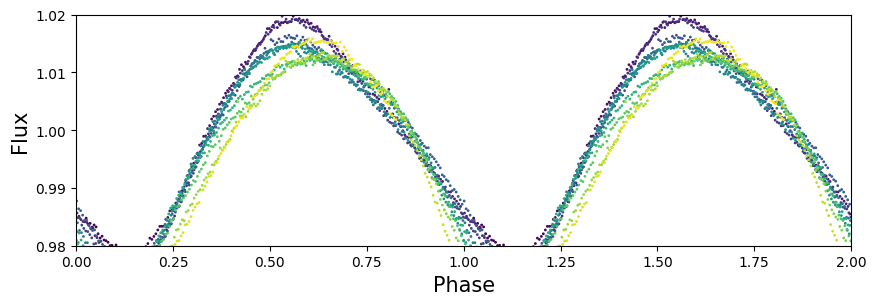

3


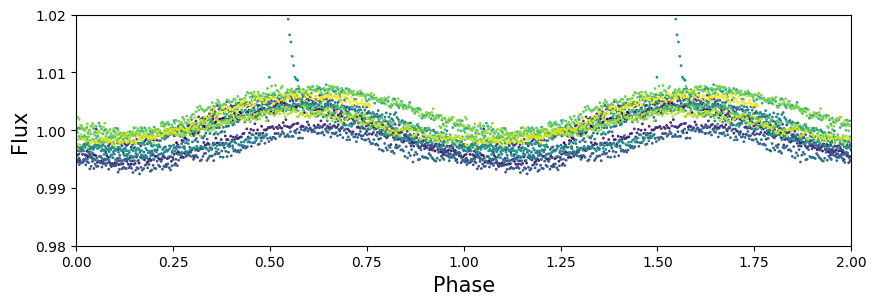

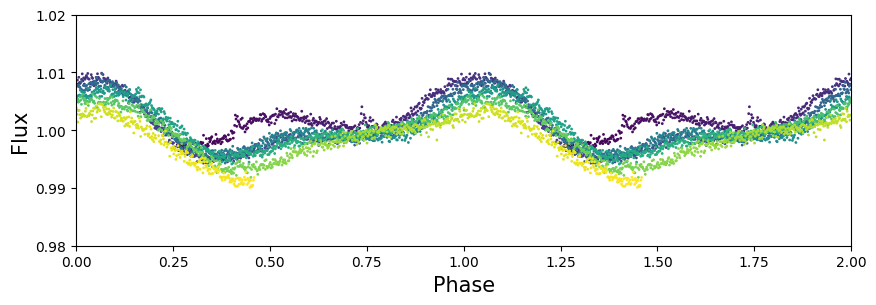

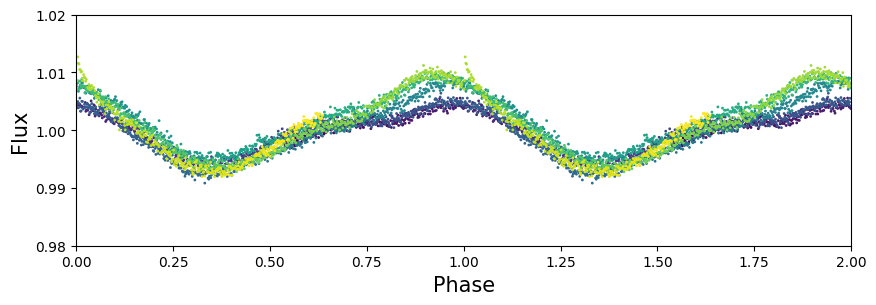

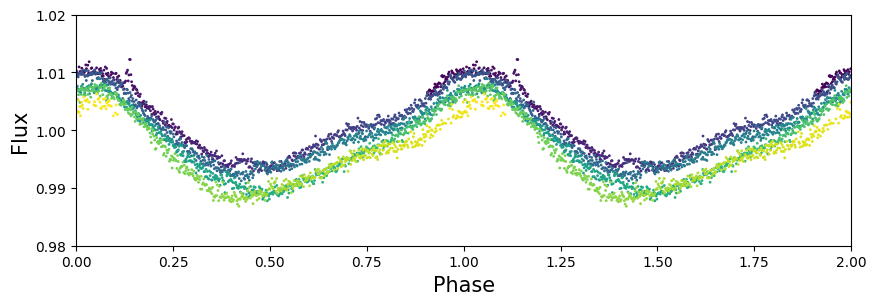

4


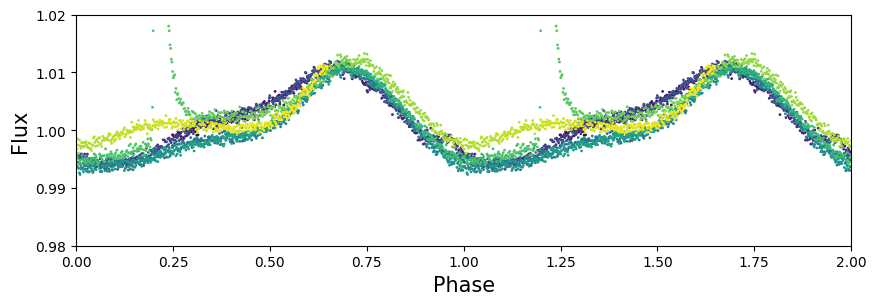

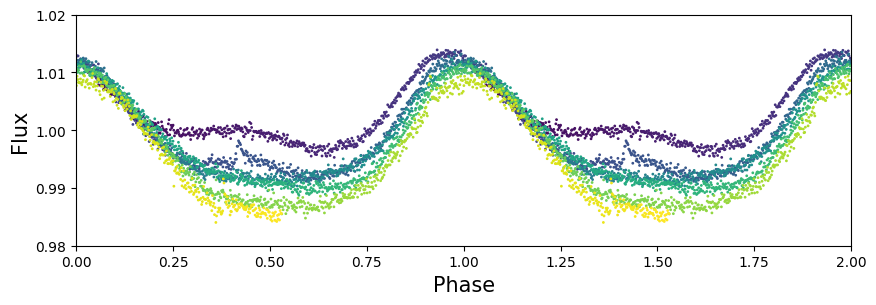

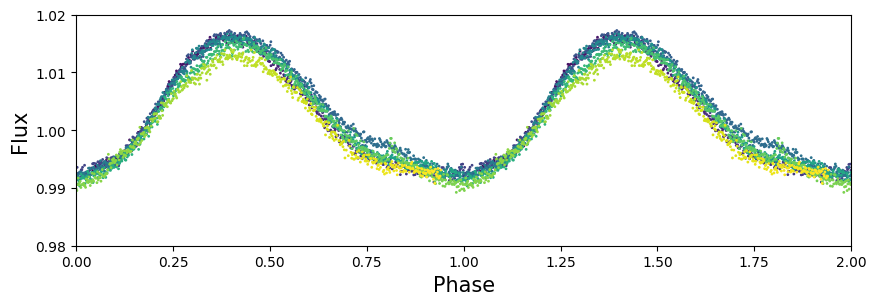

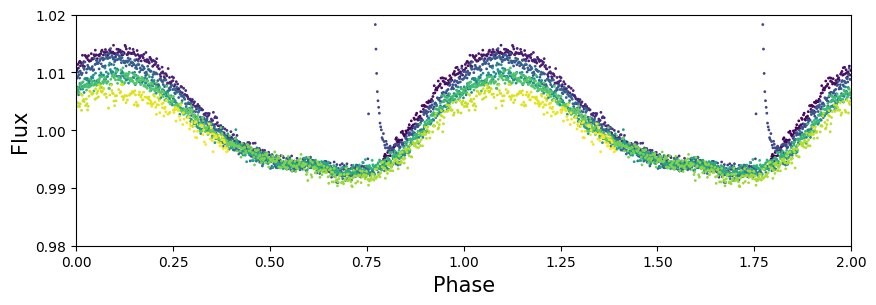

5


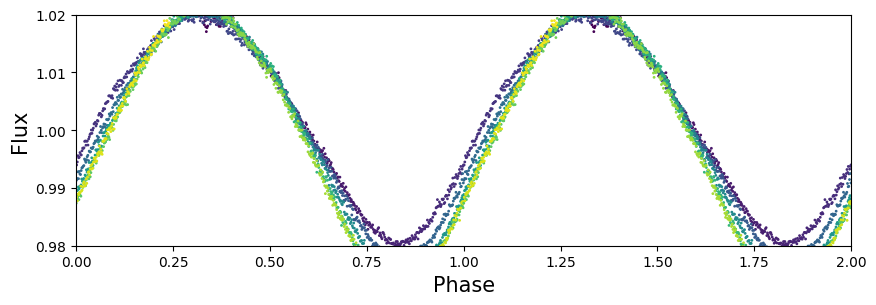

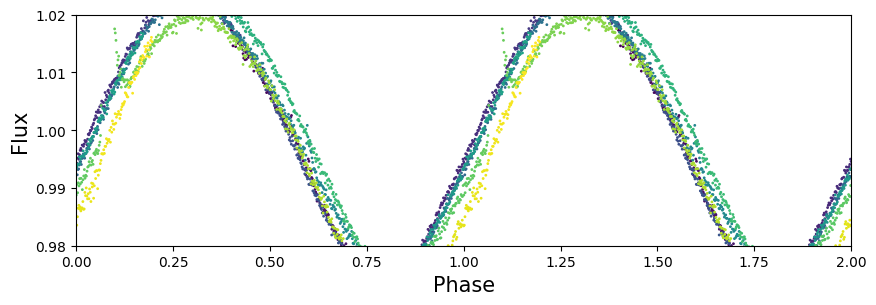

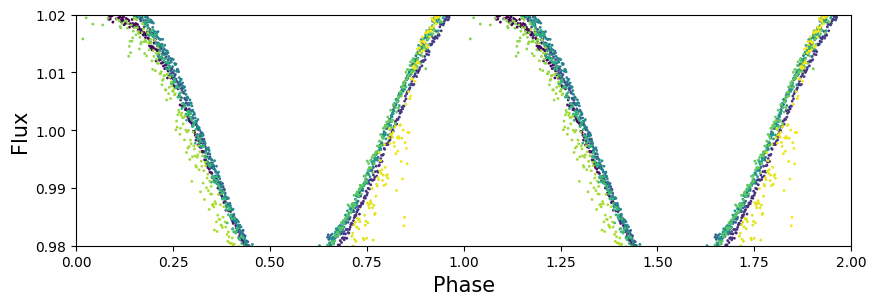

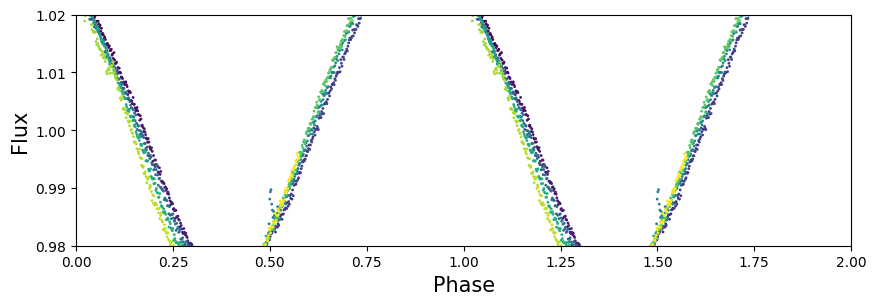

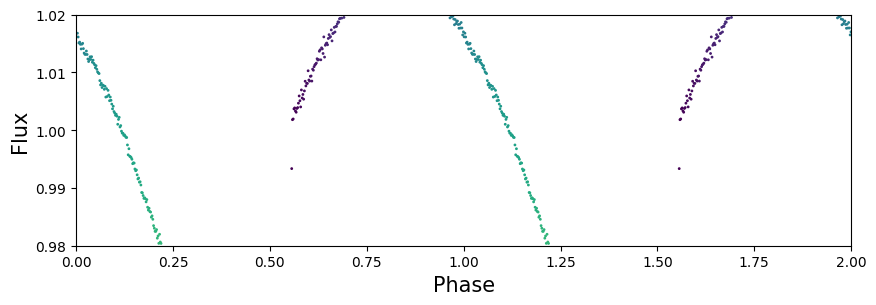

6


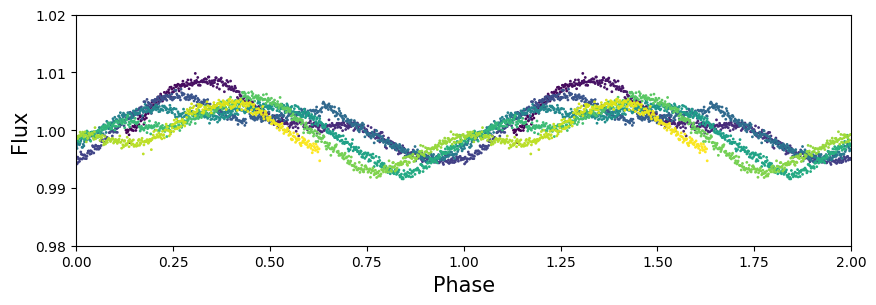

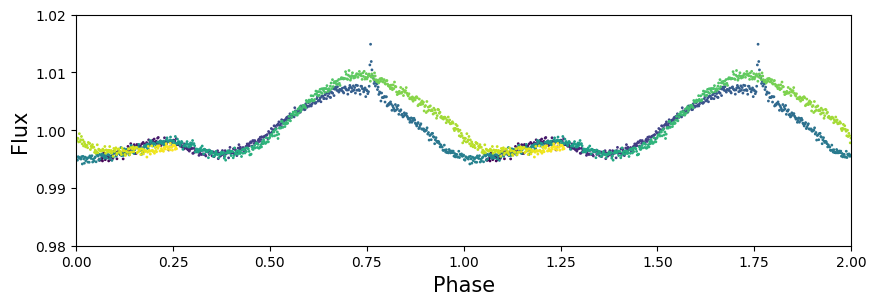

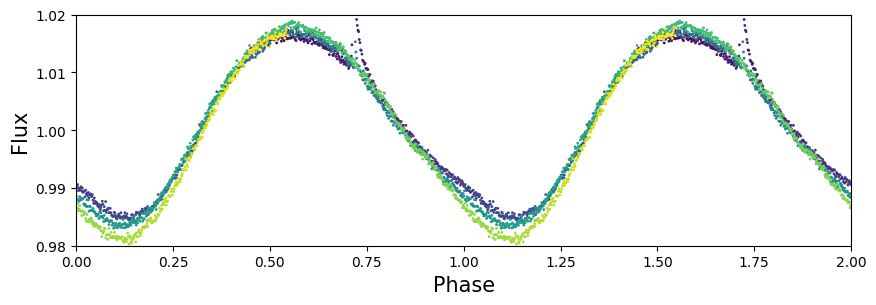

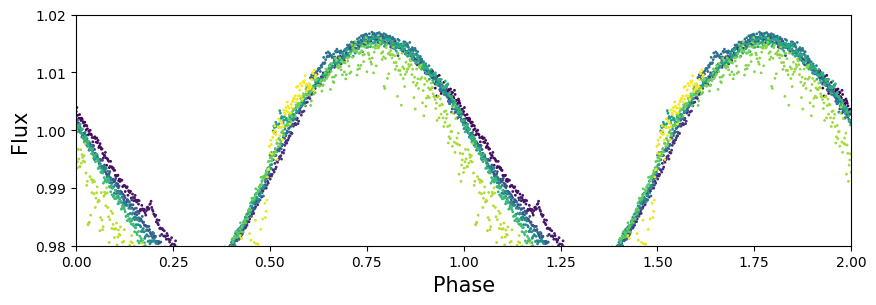

In [172]:
# Time to calculate periods!
periods = []

for i, lc_obj in enumerate(lc_list):
    print(i)

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download()

    # Segment our lightcurves
    lc_segments = segment_lc(lc, cadence)

    # Now calculate periods/plot for each segment
    for j, segment in enumerate(lc_segments):

        period, phase = find_phase_restricted_period(segment, t0)
        periods.append(period)

        phase = np.concatenate([phase, phase+1])
        flux = np.concatenate([segment.flux.value, segment.flux.value])
        time = np.concatenate([segment.time.value, segment.time.value])

        # Plot it
        plt.figure(figsize = (10,3))
        plt.scatter(phase, flux, c = time, cmap = 'viridis', s = 1)
        plt.xlim(0,2)
        plt.xlabel('Phase',fontsize=15)
        plt.ylabel('Flux',fontsize=15)
        # plt.title(f'{sector} Segment {j+1}: Period {period:.2f}',fontsize=20)
        plt.ylim(0.98, 1.02)

        if i == 4 and j == 2:
            plt.savefig('thesis_figs/hd104919-tess-phase-lc.pdf', dpi=300)
            
        plt.show()
        plt.close()

In [ ]:
# Rotation period: plot two cycles (phase 0–2)
plt.figure(figsize=(8, 4))
plt.scatter(
    np.concatenate([phase_r, phase_r + 1]),
    np.concatenate([lc.flux.value, lc.flux.value]),
    c=np.tile(lc.time.value, 2),
    cmap='viridis',
    s=1
)
plt.xlabel('Phase')
plt.ylabel('Normalised Flux')
plt.title(f'{sector}: Rotation Period {period_r:.2f} d')
plt.xlim(0, 2)
plt.ylim(0.97, 1.03)
plt.show()
plt.close()

# Binary period: plot two cycles (phase 0–2)
plt.figure(figsize=(8, 4))
plt.scatter(
    np.concatenate([phase_b, phase_b + 1]),
    np.concatenate([lc.flux.value, lc.flux.value]),
    c=np.tile(lc.time.value, 2),
    cmap='winter',
    s=1
)
plt.xlabel('Phase')
plt.ylabel('Normalised Flux')
plt.title(f'{sector}: Binary Period {period_b:.2f} d')
plt.xlim(0, 2)
plt.ylim(0.97, 1.03)
plt.show()
plt.close()

# HD 8558

In [46]:
lc_list_8558 = lk.search_lightcurve('HD 8558', author='QLP')

In [45]:
lc_list_8558

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,QLP,1800,206592394,0.0
1,TESS Sector 28,2020,QLP,600,206592394,0.0
2,TESS Sector 29,2020,QLP,600,206592394,0.0
3,TESS Sector 68,2023,QLP,200,206592394,0.0
4,TESS Sector 69,2023,QLP,200,206592394,0.0
5,TESS Sector 96,2025,QLP,200,206592394,0.0
6,TESS Sector 103,2026,QLP,200,206592394,0.0
7,TESS Sector 104,2026,QLP,200,206592394,0.0


In [177]:
lc = lc_list_8558[1].download(quality_bitmask = 'hard')
lc_all = lc_list_8558.download_all().stitch()

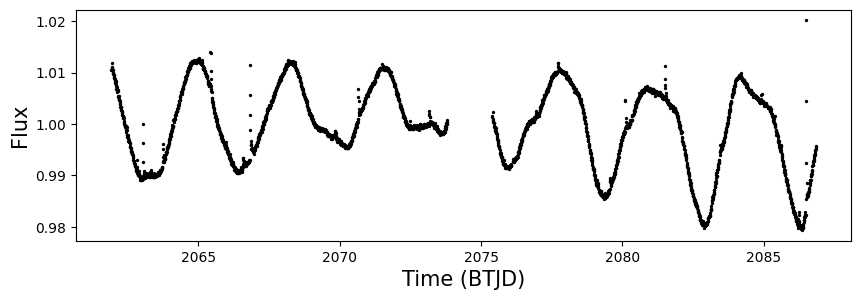

In [179]:
plt.figure(figsize = (10,3))
plt.scatter(lc.time.value, lc.flux.value, s = 2, c = 'black')
# plt.ylim(0.98,1.03)
# plt.xlim(3005,3014)
plt.xlabel('Time (BTJD)', fontsize=15)
plt.ylabel('Flux',fontsize=15)
plt.savefig('thesis_figs/hd8558-tess.pdf', dpi=300, bbox_inches='tight')

# plt.title('TYC 8927 TESS Sector 62',fontsize=20)

# HD 82533

In [64]:
lc_list_82533 = lk.search_lightcurve('HD 82533', author='QLP')

In [65]:
lc_list_82533

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 09,2019,QLP,1800,298079609,0.0
1,TESS Sector 10,2019,QLP,1800,298079609,0.0
2,TESS Sector 35,2021,QLP,600,298079609,0.0
3,TESS Sector 36,2021,QLP,600,298079609,0.0
4,TESS Sector 62,2023,QLP,200,298079609,0.0
5,TESS Sector 63,2023,QLP,200,298079609,0.0
6,TESS Sector 89,2025,QLP,200,298079609,0.0
7,TESS Sector 90,2025,QLP,200,298079609,0.0


In [180]:
lc = lc_list_82533[7].download()
lc_all = lc_list_82533.download_all().stitch()

Text(0.5, 1.0, 'TYC 8927 TESS Sector 62')

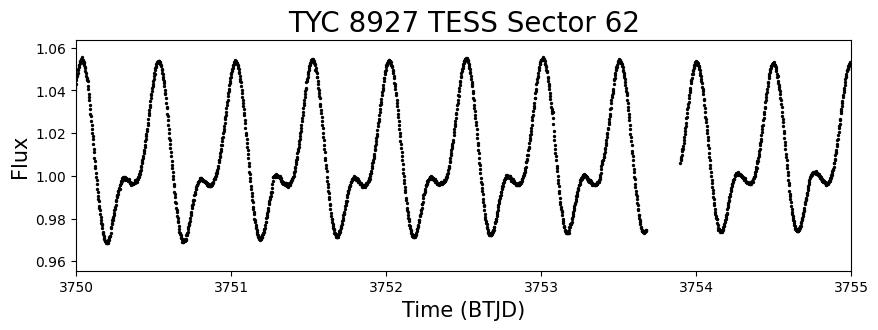

In [89]:
plt.figure(figsize = (10,3))
plt.scatter(lc.time.value, lc.flux.value, s = 2, c = 'black')
# plt.ylim(0.98,1.03)
plt.xlim(3750,3755)
plt.xlabel('Time (BTJD)', fontsize=15)
plt.ylabel('Flux',fontsize=15)
plt.title('TYC 8927 TESS Sector 62',fontsize=20)

In [76]:
freq, amp = calc_lomb_scargle(lc_all.time.value, lc_all.flux.value)

Text(0.5, 1.0, 'Periodogram - all TESS data')

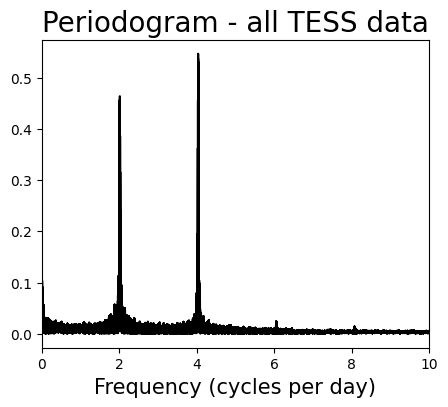

In [79]:
plt.figure(figsize = (5,4))
plt.plot(freq,amp, c = 'black')
plt.xlim(0,10)
# plt.ylim(0,0.4)
plt.xlabel('Frequency (cycles per day)', fontsize=15)
plt.title('Periodogram - all TESS data', fontsize=20)

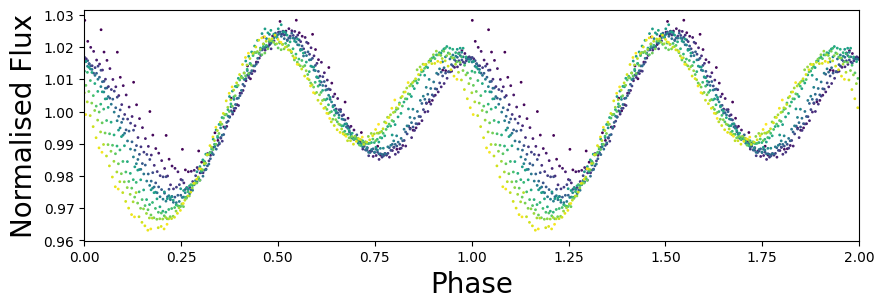

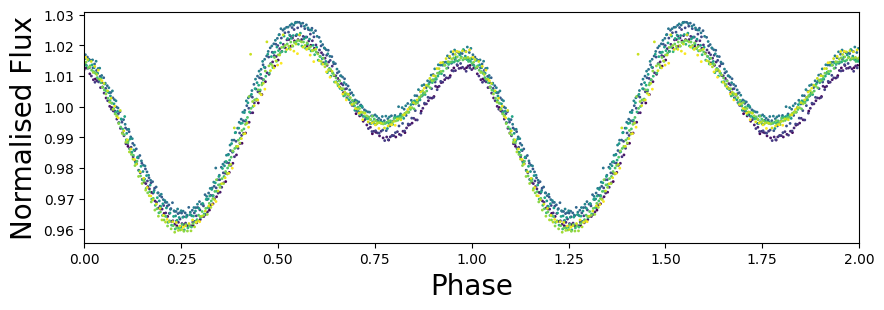

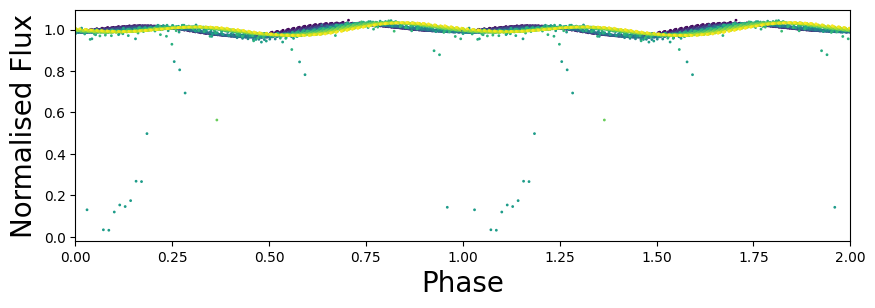

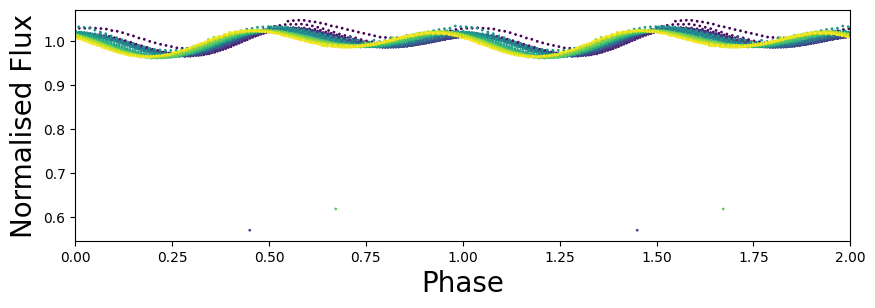

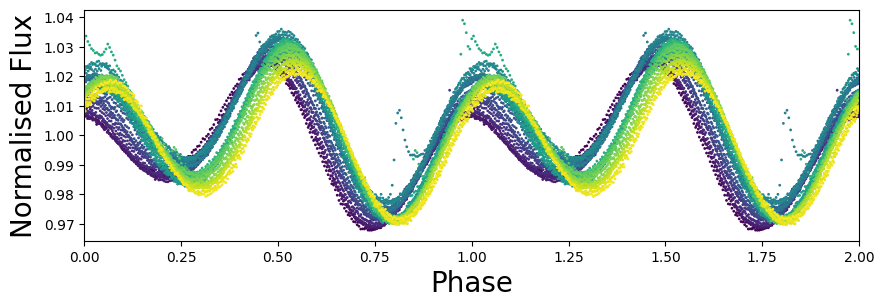

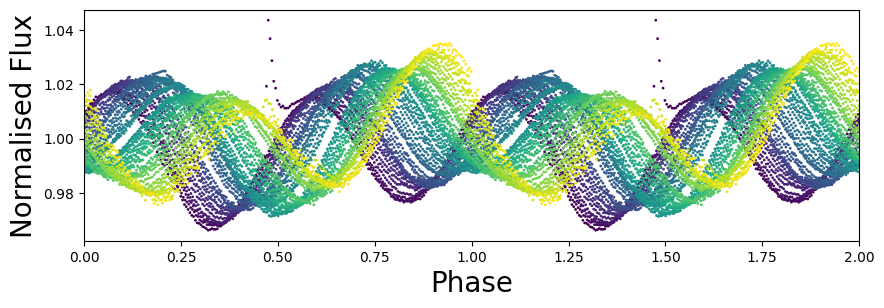

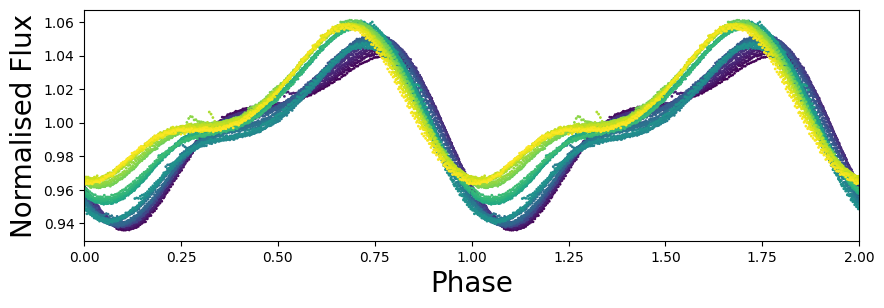

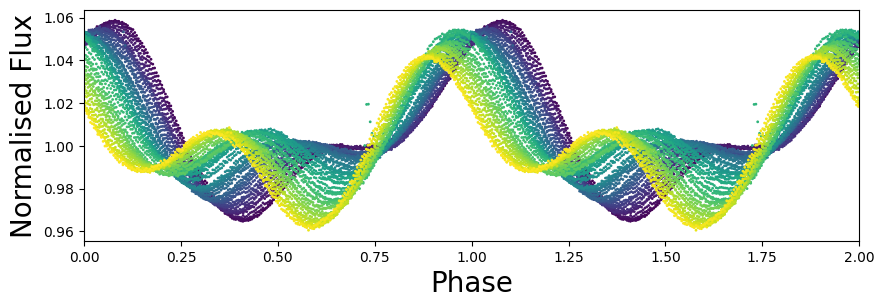

In [181]:
# Time to calculate periods!
for i , lc_obj in enumerate(lc_list_82533):

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download()
  
    period, phase = find_phase_restricted_period(lc, t0=t0, pmin=0.4, pmax = 0.6)

    # Stack 2 on top of eachother to make the pattern more clear
    phase = np.concatenate([phase, phase + 1])
    flux = np.concatenate([lc.flux.value, lc.flux.value])
    time = np.concatenate([lc.time.value, lc.time.value])

    # Plot it
    plt.figure(figsize = (10,3))
    plt.scatter(phase, flux, c = time, cmap = 'viridis', s = 1)
    plt.xlim(0,2)
    plt.xlabel('Phase', fontsize=20)
    plt.ylabel('Normalised Flux', fontsize=20)
    # plt.title(f'{sector}: Rotation Period {period:.2f}')
    # plt.ylim(0.97, 1.03)

    if i == 7:
        plt.savefig('thesis_figs/hd82533-tess.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# HD 217344

In [91]:
lc_list_217344 = lk.search_lightcurve('HD 217344', author='QLP')

In [92]:
lc_list_217344

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,QLP,1800,229066843,0.0
1,TESS Sector 02,2018,QLP,1800,229066844,0.0
2,TESS Sector 28,2020,QLP,600,229066843,0.0
3,TESS Sector 28,2020,QLP,600,229066844,0.0
4,TESS Sector 28,2020,QLP,600,2055940789,0.0
5,TESS Sector 69,2023,QLP,200,229066843,0.0
6,TESS Sector 69,2023,QLP,200,229066844,0.0
7,TESS Sector 69,2023,QLP,200,2055940789,0.0
8,TESS Sector 96,2025,QLP,200,229066844,0.0


In [173]:
lc = lc_list_217344[5].download(quality_bitmask = 'hard')
lc_all = lc_list_217344.download_all(quality_bitmask = 'hard').stitch()

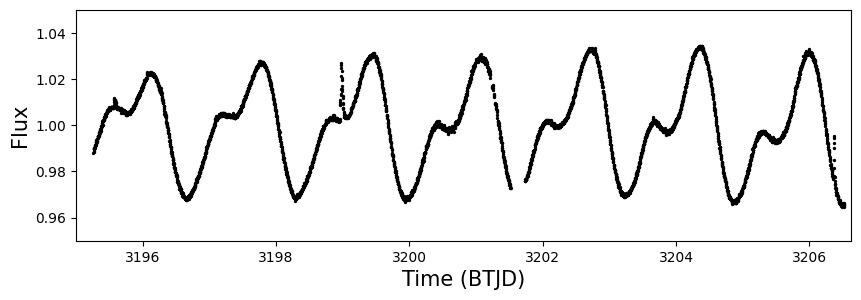

In [176]:
plt.figure(figsize = (10,3))
plt.scatter(lc.time.value, lc.flux.value, s = 2, c = 'black')
plt.ylim(0.95, 1.05)
plt.xlim(3195, np.max(lc.time.value)+0.1)
plt.xlabel('Time (BTJD)', fontsize=15)
plt.ylabel('Flux',fontsize=15)
plt.savefig('thesis_figs/hd217344-tess.pdf', dpi=300, bbox_inches='tight')
# plt.title('TYC 8927 TESS Sector 62',fontsize=20)

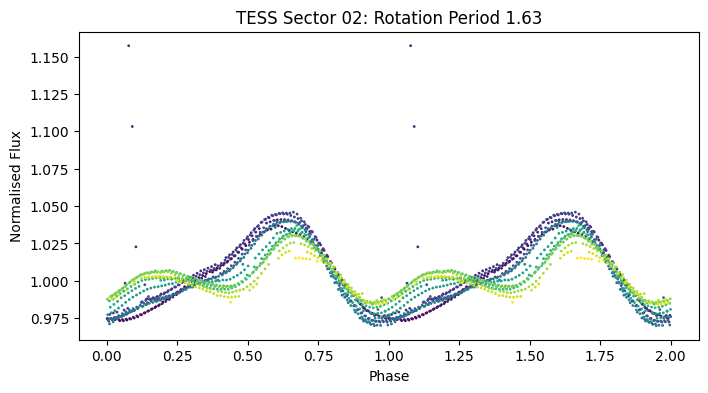

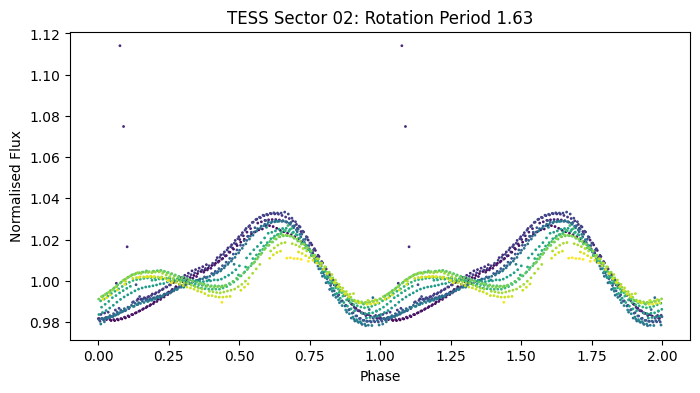

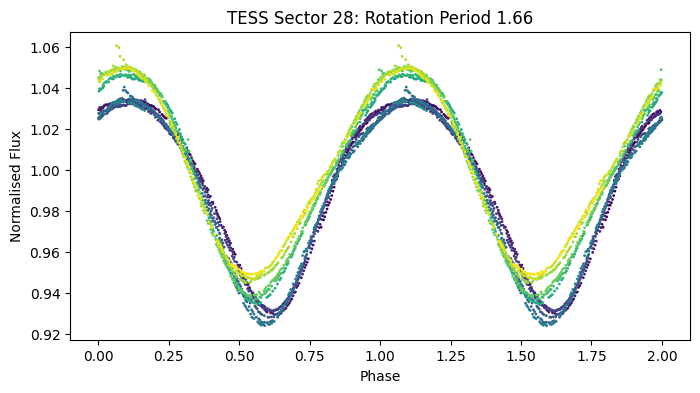

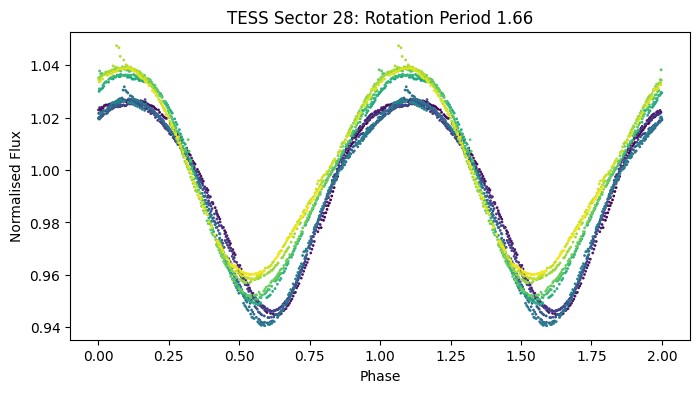

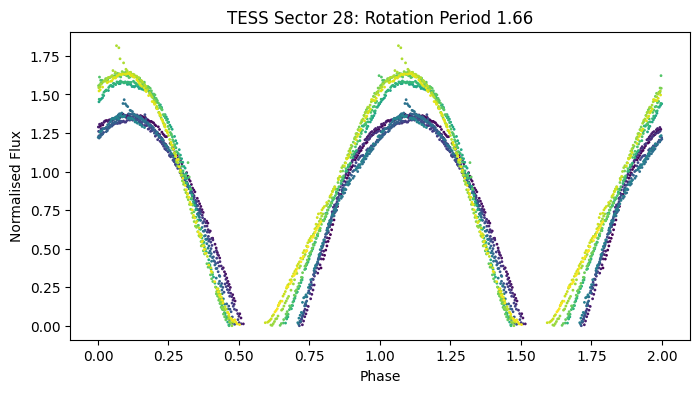

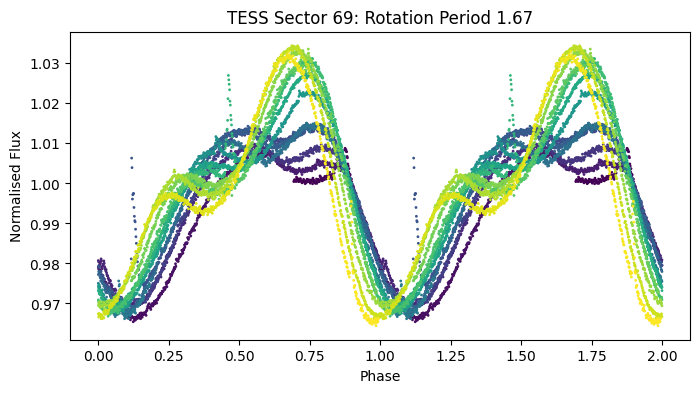

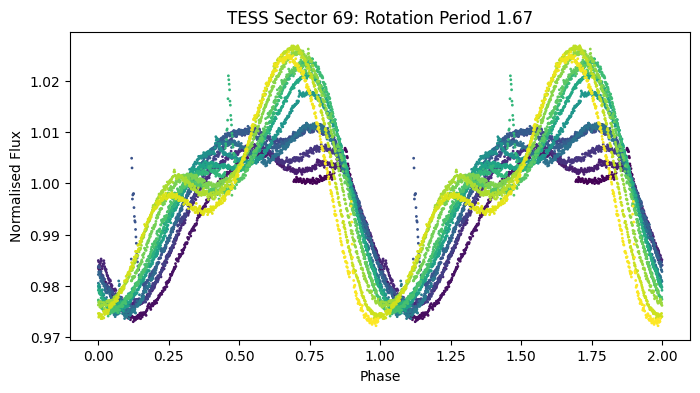

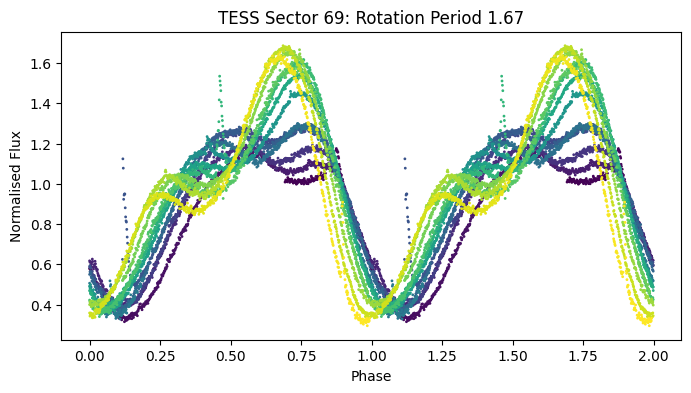

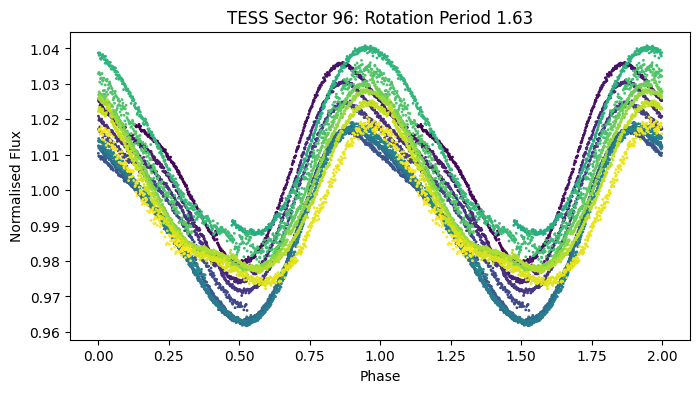

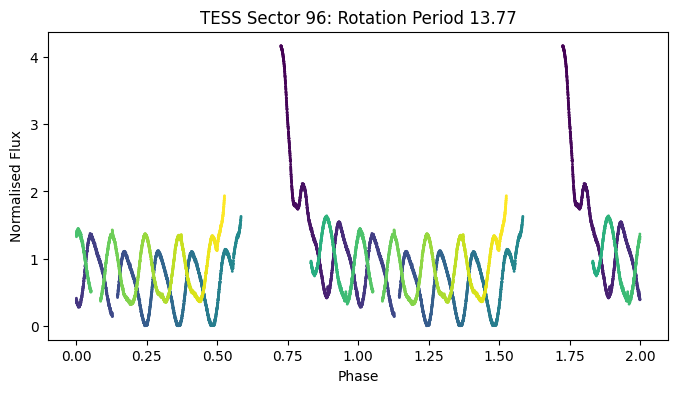

In [113]:
# Time to calculate periods!
for lc_obj in lc_list_217344:

    # Sector name
    sector = lc_obj.mission[0]

    # Find the cadence
    cadence = lc_obj.exptime.value[0] / 60 / 60 / 24

    # Go from list --> LC
    lc = lc_obj.download(quality_bitmask = 'hard')
  
    period, phase = find_phase_restricted_period(lc, t0=t0)

    # Stack 2 on top of eachother to make the pattern more clear
    phase = np.concatenate([phase, phase + 1])
    flux = np.concatenate([lc.flux.value, lc.flux.value])
    time = np.concatenate([lc.time.value, lc.time.value])

    # Plot it
    plt.figure(figsize = (8,4))
    plt.scatter(phase, flux, c = time, cmap = 'viridis', s = 1)
    plt.xlabel('Phase')
    plt.ylabel('Normalised Flux')
    plt.title(f'{sector}: Rotation Period {period:.2f}')
    # plt.ylim(0.97, 1.03)
    plt.show()
    plt.close()

In [132]:
freq, amp = calc_lomb_scargle(lc_all.time.value, lc_all.flux.value)

Text(0.5, 1.0, 'Periodogram - all TESS data')

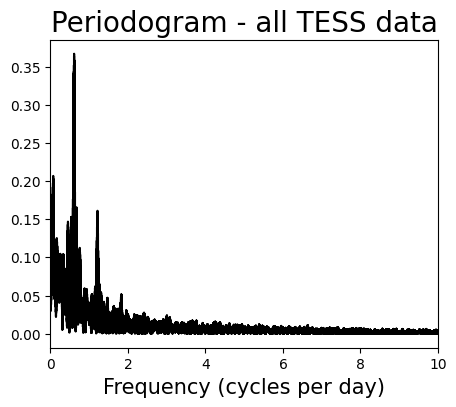

In [133]:
plt.figure(figsize = (5,4))
plt.plot(freq,amp, c = 'black')
plt.xlim(0,10)
# plt.ylim(0,0.4)
plt.xlabel('Frequency (cycles per day)', fontsize=15)
plt.title('Periodogram - all TESS data', fontsize=20)